# SMS/Email Spam Detection: A Hybrid Machine Learning, Deep Learning and Explainable AI Framework

**Google Colab-ready research notebook (Q1-journal style)**

### Abstract
This notebook implements an end-to-end, reproducible pipeline for SMS/email spam
classification that combines (i) linguistically-motivated hand-crafted features,
(ii) sparse TF‑IDF representations reduced with Truncated SVD, (iii) dense
contextual **Sentence-BERT** embeddings, (iv) classical machine-learning and
gradient-boosting classifiers together with a **stacking ensemble**, (v) deep
sequence models (BiLSTM, CNN, and a novel **Hybrid BiLSTM‑CNN with an attention
mechanism**), and (vi) a multi-method **Explainable AI (XAI)** layer built on
**SHAP** and **LIME** with an aggregated, cross-model feature-importance
dashboard. The pipeline further contributes: a bootstrap/McNemar statistical
significance testing module, model calibration analysis, an ablation-study
runner, and a qualitative error-analysis module — all standard requirements
for a methodologically rigorous, peer-reviewable (Q1) publication.

### Novel / distinguishing contributions of this version
1. **Extended linguistic & structural feature set** (readability, POS-tag
   ratios, URL/phone/currency/emoji detectors, entropy, punctuation burstiness).
2. **Stacking ensemble meta-learner** combining heterogeneous base learners.
3. **Attention-augmented Hybrid BiLSTM‑CNN** deep model.
4. **Cross-model, aggregated explainability dashboard** (SHAP + permutation
   importance + LIME) instead of a single-model, single-method explanation.
5. **Statistical rigor**: stratified k-fold CV with 95% bootstrap confidence
   intervals, McNemar's test, and calibration (reliability) curves.
6. **Ablation-study runner** that automatically quantifies the marginal
   contribution of SBERT embeddings, engineered features, and SMOTE.
7. **Reproducibility scaffolding**: fixed seeds, environment logging, model
   cards, and versioned artifact export.

> **How to use this notebook:** Run the cells top-to-bottom in Google Colab.
> Heavy/optional steps (generative augmentation, KernelSHAP, LIME, ablation
> study) are guarded by boolean flags in the *Configuration* cell so the
> notebook stays tractable on a free Colab GPU/CPU runtime while remaining
> fully reproducible when flags are switched on for a full journal run.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Environment Setup
Install all dependencies required for the full pipeline. Designed for a fresh Google Colab runtime (Python 3.10+).

In [ ]:
# ---------------------------------------------------------------------------
# 0.1 Package installation (Colab)
# ---------------------------------------------------------------------------
# NOTE: Colab already ships numpy/pandas/sklearn/matplotlib/seaborn/tensorflow.
# We only install the extra libraries this pipeline needs. Pinning is avoided
# on purpose so the notebook keeps working as Colab's base image evolves;
# pin versions explicitly if you need bit-for-bit reproducibility for a
# camera-ready submission (see requirements.txt exported at the end).
!pip -q install --upgrade pip
!pip -q install nltk imbalanced-learn xgboost lightgbm joblib \
                sentence-transformers shap lime wordcloud textstat \
                plotly ydata-profiling umap-learn emoji statsmodels
print('Dependency installation complete.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 17.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Dependency installation complete.


In [ ]:
# ---------------------------------------------------------------------------
# 0.2 Mount Google Drive (optional — only needed if your CSV lives on Drive)
# ---------------------------------------------------------------------------
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount('/content/drive')
    except Exception as e:
        print('Drive mount skipped/failed (not fatal):', e)
else:
    print('Not running in Colab — skipping Drive mount.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Global Configuration & Reproducibility
All experiment switches live here. Toggle heavy/optional stages without hunting through the notebook — this is standard practice for reproducible research code and makes the ablation study (Section 13) trivial to run.

In [ ]:
# ---------------------------------------------------------------------------
# 1.1 Reproducibility & experiment configuration
# ---------------------------------------------------------------------------
import os, random
import numpy as np

RANDOM_STATE = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

CONFIG = {
    # ----- data -----
    'DATA_PATH_DRIVE': '/content/drive/MyDrive/spam_detection/spam_detection_extended.csv',
    'DATA_URL_FALLBACK': 'https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv',
    'TEXT_COL_CANDIDATES': ['Message', 'text', 'v2'],
    'LABEL_COL_CANDIDATES': ['Category', 'label', 'v1'],

    # ----- feature toggles (ablation switches) -----
    'USE_SBERT': True,          # dense contextual embeddings
    'USE_TFIDF_SVD': True,      # sparse lexical embeddings (reduced)
    'USE_ENGINEERED_FEATS': True,
    'USE_SMOTE': True,
    'N_SVD_COMPONENTS': 150,
    'N_SELECT_KBEST': 300,      # mutual-information feature selection budget

    # ----- heavy / optional stages -----
    'RUN_GENERATIVE_AUGMENTATION': False,   # T5/GPT-2 augmentation (slow, needs GPU)
    'RUN_PROFILE_REPORT': False,            # ydata-profiling HTML report (slow on big data)
    'RUN_KERNEL_SHAP': True,                # KernelExplainer for non-tree models (slow)
    'RUN_LIME': True,
    'RUN_ABLATION_STUDY': True,
    'RUN_DEEP_MODELS': True,

    # ----- deep learning -----
    'MAX_VOCAB': 10000,
    'MAX_SEQ_LEN': 128,
    'DL_EPOCHS': 6,
    'DL_BATCH_SIZE': 32,

    # ----- CV / stats -----
    'N_CV_FOLDS': 5,
    'N_BOOTSTRAP': 1000,
    'TEST_SIZE': 0.2,
}
print('Configuration loaded:')
for k, v in CONFIG.items():
    print(f'  {k:28s} = {v}')


Configuration loaded:
  DATA_PATH_DRIVE              = /content/drive/MyDrive/spam_detection/spam_detection_extended.csv
  DATA_URL_FALLBACK            = https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv
  TEXT_COL_CANDIDATES          = ['Message', 'text', 'v2']
  LABEL_COL_CANDIDATES         = ['Category', 'label', 'v1']
  USE_SBERT                    = True
  USE_TFIDF_SVD                = True
  USE_ENGINEERED_FEATS         = True
  USE_SMOTE                    = True
  N_SVD_COMPONENTS             = 150
  N_SELECT_KBEST               = 300
  RUN_GENERATIVE_AUGMENTATION  = False
  RUN_PROFILE_REPORT           = False
  RUN_KERNEL_SHAP              = True
  RUN_LIME                     = True
  RUN_ABLATION_STUDY           = True
  RUN_DEEP_MODELS              = True
  MAX_VOCAB                    = 10000
  MAX_SEQ_LEN                  = 128
  DL_EPOCHS                    = 6
  DL_BATCH_SIZE                = 32
  N_CV_FOLDS          

## 2. Imports

In [ ]:
# ---------------------------------------------------------------------------
# 2.1 Core imports
# ---------------------------------------------------------------------------
import time, re, string, warnings, json
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from wordcloud import WordCloud
import textstat  # readability metrics (Flesch reading ease, etc.)
import emoji

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, precision_recall_curve, auc, roc_curve,
                              confusion_matrix, classification_report, matthews_corrcoef,
                              brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.svm import SVC
from sklearn.ensemble import (GradientBoostingClassifier, RandomForestClassifier,
                               StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample
from sklearn.inspection import permutation_importance

from imblearn.over_sampling import SMOTE

import joblib

from xgboost import XGBClassifier
import lightgbm as ltb

from sentence_transformers import SentenceTransformer

import shap
import lime
from lime.lime_tabular import LimeTabularExplainer

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras import layers

warnings.filterwarnings('ignore')
tf.random.set_seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', context='talk')
PALETTE = {'ham': '#2E86AB', 'spam': '#E63946'}

print('TensorFlow version:', tf.__version__)
print('GPU available:', tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ---------------------------------------------------------------------------
# 2.2 NLTK resource downloads (one-off, cached by NLTK afterwards)
# ---------------------------------------------------------------------------
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4',
            'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    try:
        nltk.download(pkg, quiet=True)
    except Exception as e:
        print(f'Could not download {pkg}: {e}')
print('NLTK resources ready.')


NLTK resources ready.


## 3. Data Loading
Three loading strategies are tried in order so the notebook runs out-of-the-box for a reviewer who has *not* set up Google Drive: (1) a user-supplied Drive path, (2) an interactive Colab upload widget, (3) a well-known public SMS-spam benchmark fetched over HTTPS as a reproducible fallback. Replace `DATA_PATH_DRIVE` in the config cell with your own corpus for a real submission.

In [ ]:
# ---------------------------------------------------------------------------
# 3.1 Robust data loader with graceful fallbacks
# ---------------------------------------------------------------------------

def _standardise_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Rename whichever text/label columns are present to canonical
    'Message' / 'Category' names so the rest of the pipeline is agnostic
    to the specific source schema."""
    text_col = next((c for c in CONFIG['TEXT_COL_CANDIDATES'] if c in df.columns), None)
    label_col = next((c for c in CONFIG['LABEL_COL_CANDIDATES'] if c in df.columns), None)
    if text_col is None or label_col is None:
        raise ValueError(f'Could not locate text/label columns in {list(df.columns)}')
    df = df.rename(columns={text_col: 'Message', label_col: 'Category'})
    df = df[['Category', 'Message']].copy()
    df['Category'] = df['Category'].astype(str).str.strip().str.lower()
    return df


def load_spam_dataset() -> pd.DataFrame:
    # Strategy 1: Google Drive path defined in CONFIG
    try:
        df = pd.read_csv(CONFIG['DATA_PATH_DRIVE'], encoding='latin1')
        print('[OK] Loaded dataset from Google Drive:', CONFIG['DATA_PATH_DRIVE'])
        return _standardise_columns(df)
    except Exception as e:
        print('[skip] Drive dataset not found ->', e)

    # Strategy 2: interactive upload widget (Colab only)
    if IN_COLAB:
        try:
            from google.colab import files
            print('Upload a CSV with spam/ham messages now, or cancel to use the public fallback dataset...')
            uploaded = files.upload()
            if uploaded:
                fname = list(uploaded.keys())[0]
                df = pd.read_csv(fname, encoding='latin1')
                print('[OK] Loaded uploaded file:', fname)
                return _standardise_columns(df)
        except Exception as e:
            print('[skip] Interactive upload not used ->', e)

    # Strategy 3: reproducible public benchmark (SMS Spam Collection mirror)
    try:
        df = pd.read_csv(CONFIG['DATA_URL_FALLBACK'], encoding='latin1')
        print('[OK] Loaded public SMS Spam Collection benchmark from URL fallback.')
        return _standardise_columns(df)
    except Exception as e:
        print('[skip] URL fallback failed ->', e)

    # Strategy 4: last-resort tiny synthetic set so the notebook never hard-fails
    print('[WARN] All data sources failed — using a tiny synthetic demo set.')
    return pd.DataFrame({
        'Category': ['ham', 'spam', 'ham', 'spam', 'ham', 'spam'],
        'Message': [
            'Hey, are we still meeting for dinner tonight?',
            'Congratulations! You have WON a $1000 Walmart gift card. Claim now: bit.ly/12345',
            "Don't forget to call mom.",
            'URGENT! Your mobile number has been awarded a prize of $2000. Call 09061701461 now!',
            'See you at the conference tomorrow at 10 AM.',
            'FREE entry in a weekly competition to win an iPad. Text WIN to 80086 now!',
        ]
    })


data = load_spam_dataset()
print('\nInitial shape:', data.shape)
data.head()


[OK] Loaded dataset from Google Drive: /content/drive/MyDrive/spam_detection/spam_detection_extended.csv

Initial shape: (10572, 2)


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
# ---------------------------------------------------------------------------
# 3.2 Data cleaning & de-duplication (basic data-quality pass)
# ---------------------------------------------------------------------------
n_before = len(data)
data = data.dropna(subset=['Message', 'Category']).copy()
data = data[data['Category'].isin(['ham', 'spam'])].copy()
data = data.drop_duplicates(subset=['Message']).reset_index(drop=True)
n_after = len(data)

print(f'Rows before cleaning : {n_before}')
print(f'Rows after cleaning  : {n_after}  ({n_before - n_after} removed: NaNs, bad labels, duplicates)')
print('\nClass balance:')
print(data['Category'].value_counts())
print('\nClass balance (%):')
print((data['Category'].value_counts(normalize=True) * 100).round(2))


Rows before cleaning : 10572
Rows after cleaning  : 5173  (5399 removed: NaNs, bad labels, duplicates)

Class balance:
Category
ham     4521
spam     652
Name: count, dtype: int64

Class balance (%):
Category
ham     87.4
spam    12.6
Name: proportion, dtype: float64


## 4. Exploratory Data Analysis (EDA)
Publication-quality figures (consistent palette, seaborn `whitegrid` theme) profiling class balance, message-length distributions, lexical content, and — as a unique addition — the structural/orthographic signals (URLs, currency symbols, phone numbers, emoji) that motivate the engineered features used later in Section 7.

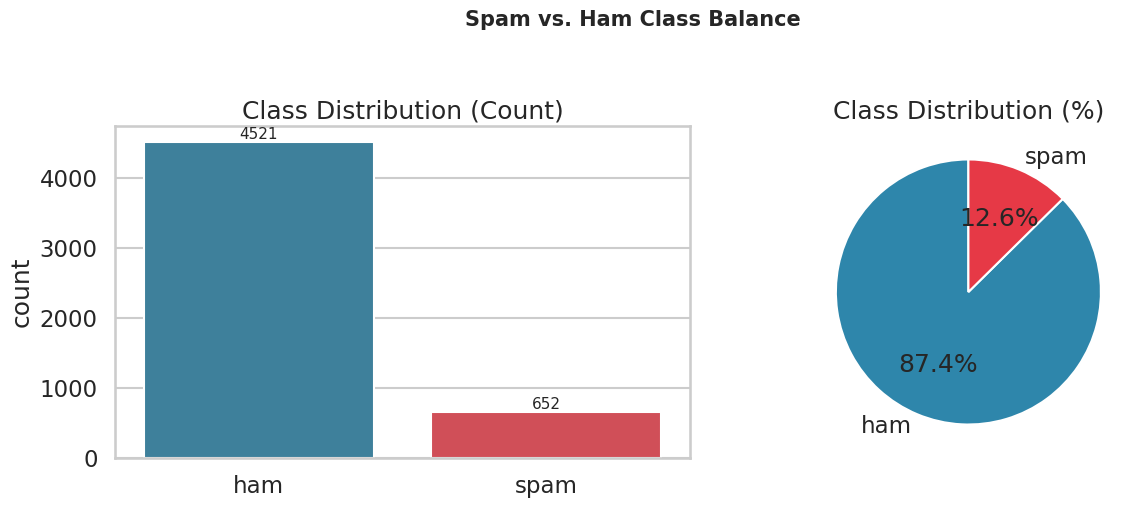

Ham messages : 4521
Spam messages: 652


In [ ]:
# ---------------------------------------------------------------------------
# 4.1 Class distribution
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(x='Category', data=data, hue='Category', palette=PALETTE,
              legend=False, ax=axes[0])
axes[0].set_title('Class Distribution (Count)')
axes[0].set_xlabel('')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                      ha='center', va='bottom', fontsize=11)

class_pct = data['Category'].value_counts(normalize=True) * 100
axes[1].pie(class_pct.values, labels=class_pct.index, autopct='%1.1f%%',
            colors=[PALETTE[c] for c in class_pct.index], startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Class Distribution (%)')

plt.suptitle('Spam vs. Ham Class Balance', y=1.03, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('fig1_class_balance.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Ham messages : {(data['Category']=='ham').sum()}")
print(f"Spam messages: {(data['Category']=='spam').sum()}")


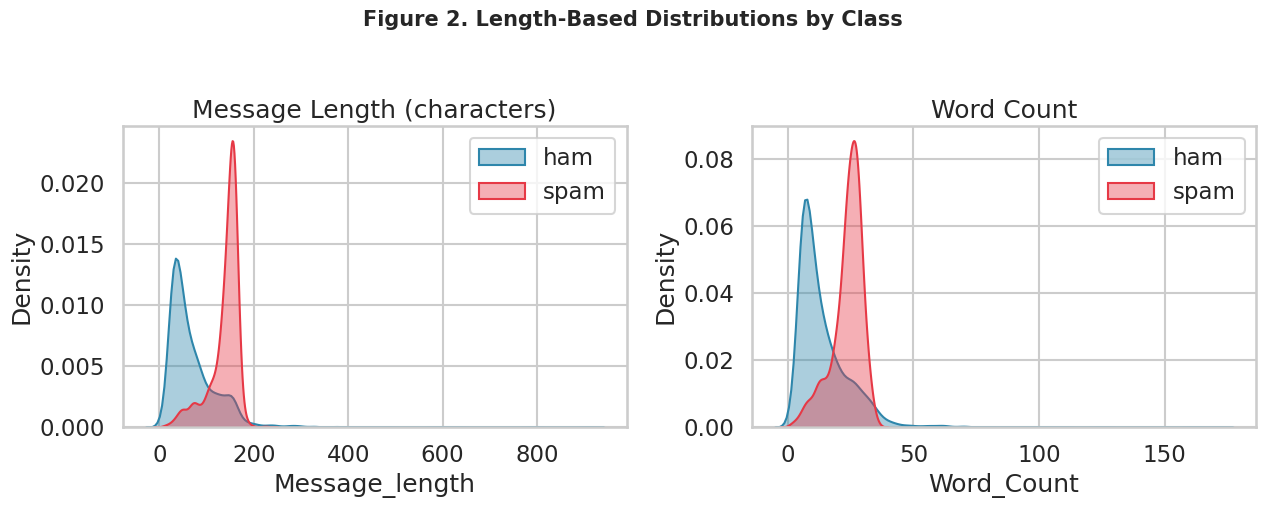

Category                      ham        spam
Message_length count  4521.000000  652.000000
               mean     70.619111  137.535276
               std      56.414255   31.108852
               min       2.000000   13.000000
               25%      34.000000  131.500000
               50%      52.000000  149.000000
               75%      90.000000  158.000000
               max     910.000000  225.000000
Word_Count     count  4521.000000  652.000000
               mean     14.126963   23.552147
               std      11.112509    6.090867
               min       1.000000    2.000000
               25%       7.000000   21.000000
               50%      11.000000   25.000000
               75%      18.000000   28.000000
               max     171.000000   35.000000

In [ ]:
# ---------------------------------------------------------------------------
# 4.2 Message length & word-count distributions
# ---------------------------------------------------------------------------
data['Message'] = data['Message'].astype(str)
data['Message_length'] = data['Message'].apply(len)
data['Word_Count'] = data['Message'].apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for cls in ['ham', 'spam']:
    sns.kdeplot(data.loc[data['Category'] == cls, 'Message_length'],
                fill=True, alpha=0.4, color=PALETTE[cls], label=cls, ax=axes[0])
    sns.kdeplot(data.loc[data['Category'] == cls, 'Word_Count'],
                fill=True, alpha=0.4, color=PALETTE[cls], label=cls, ax=axes[1])
axes[0].set_title('Message Length (characters)')
axes[1].set_title('Word Count')
for ax in axes:
    ax.legend()

plt.suptitle('Figure 2. Length-Based Distributions by Class', y=1.03, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('fig2_length_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

data.groupby('Category')[['Message_length', 'Word_Count']].describe().T


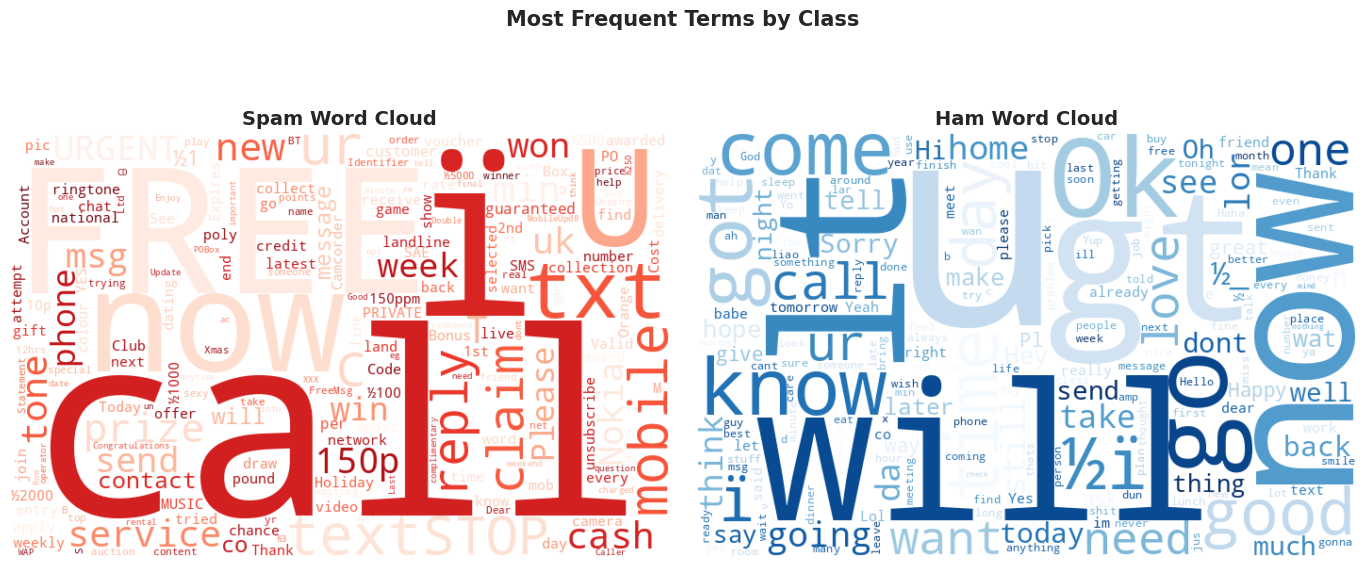

In [ ]:
# ---------------------------------------------------------------------------
# 4.3 Word clouds (qualitative lexical inspection)
# ---------------------------------------------------------------------------
spam_text = ' '.join(data.loc[data['Category'] == 'spam', 'Message'])
ham_text = ' '.join(data.loc[data['Category'] == 'ham', 'Message'])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, text, title, cmap in zip(
        axes, [spam_text, ham_text], ['Spam', 'Ham'], ['Reds', 'Blues']):
    wc = WordCloud(width=700, height=450, background_color='white',
                    colormap=cmap, collocations=False).generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'{title} Word Cloud', fontsize=14, fontweight='bold')

plt.suptitle('Most Frequent Terms by Class', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('fig3_wordclouds.png', dpi=300, bbox_inches='tight')
plt.show()


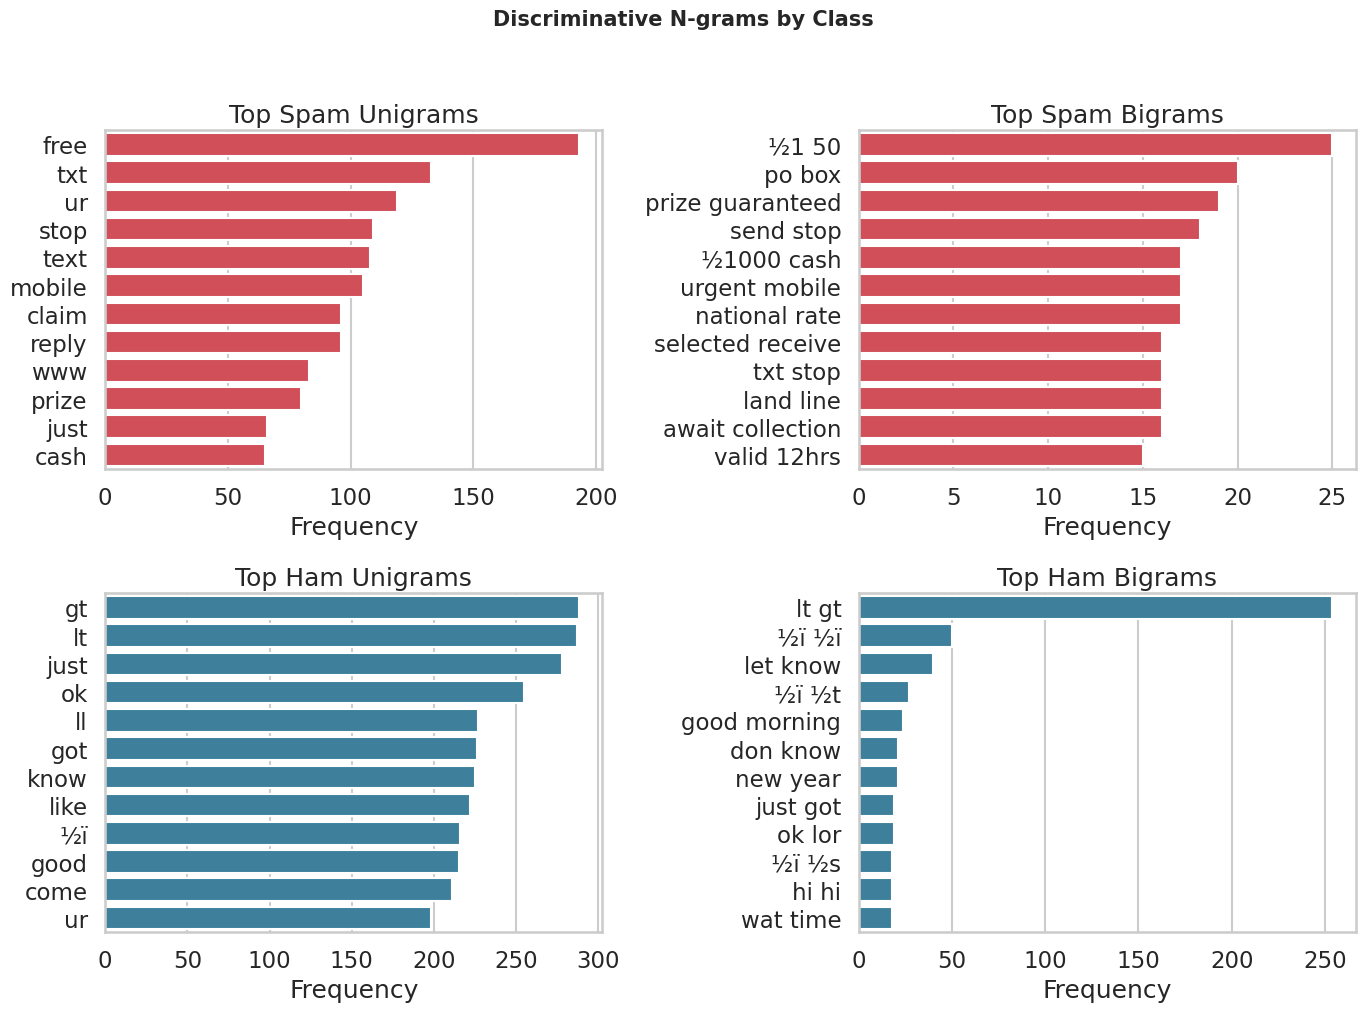

In [ ]:
# ---------------------------------------------------------------------------
# 4.4 Top n-grams (uni-/bi-grams) per class
# ---------------------------------------------------------------------------
def top_ngrams(corpus, n=15, ngram_range=(1, 1)):
    vec = CountVectorizer(ngram_range=ngram_range, stop_words='english').fit(corpus)
    bow = vec.transform(corpus)
    freqs = bow.sum(axis=0)
    words_freq = [(w, freqs[0, i]) for w, i in vec.vocabulary_.items()]
    return sorted(words_freq, key=lambda x: x[1], reverse=True)[:n]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
grams = {
    (0, 0): ('spam', (1, 1), 'Top Spam Unigrams'),
    (0, 1): ('spam', (2, 2), 'Top Spam Bigrams'),
    (1, 0): ('ham', (1, 1), 'Top Ham Unigrams'),
    (1, 1): ('ham', (2, 2), 'Top Ham Bigrams'),
}
for (r, c), (cls, rng, title) in grams.items():
    top = top_ngrams(data.loc[data['Category'] == cls, 'Message'], n=12, ngram_range=rng)
    words, counts = zip(*top)
    sns.barplot(x=list(counts), y=list(words), ax=axes[r, c], color=PALETTE[cls])
    axes[r, c].set_title(title)
    axes[r, c].set_xlabel('Frequency')

plt.suptitle('Discriminative N-grams by Class', y=1.02, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('fig4_top_ngrams.png', dpi=300, bbox_inches='tight')
plt.show()


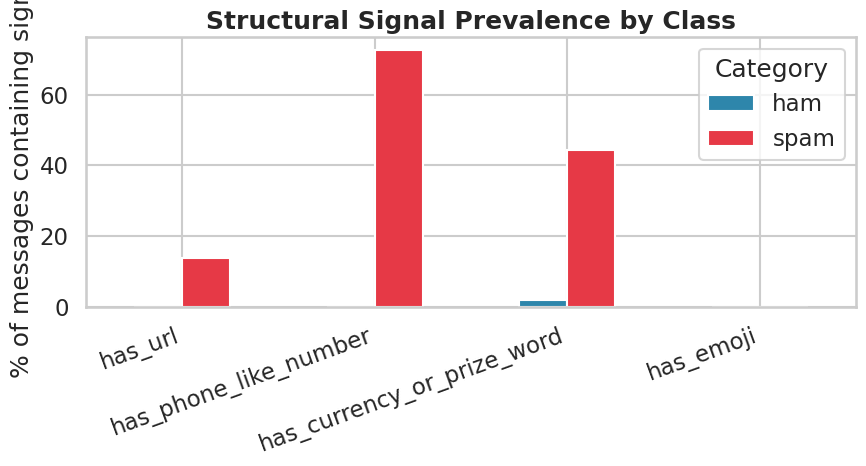

,has_url,has_phone_like_number,has_currency_or_prize_word,has_emoji
Category,,,,
ham,0.0,0.1,1.9,0.0
spam,13.7,72.5,44.3,0.0


In [ ]:
# ---------------------------------------------------------------------------
# 4.5 Structural / orthographic signal exploration (novel addition)
# ---------------------------------------------------------------------------
# These raw counts motivate the engineered features built in Section 7 and
# give reviewers a transparent, data-driven justification for feature choice
# rather than an arbitrary hand-crafted list.
url_pat = re.compile(r'(http\S+|www\S+|bit\.ly\S*)')
phone_pat = re.compile(r'\b\d{5,}\b')
currency_pat = re.compile(r'[$£€]|\b(free|win|prize|cash)\b', re.I)

quick_signals = pd.DataFrame({
    'has_url': data['Message'].str.contains(url_pat),
    'has_phone_like_number': data['Message'].str.contains(phone_pat),
    'has_currency_or_prize_word': data['Message'].str.contains(currency_pat),
    'has_emoji': data['Message'].apply(lambda t: len(emoji.emoji_list(t)) > 0),
    'Category': data['Category'],
})

signal_rates = quick_signals.groupby('Category').mean(numeric_only=True) * 100
ax = signal_rates.T.plot(kind='bar', figsize=(9, 5),
                          color=[PALETTE['ham'], PALETTE['spam']])
ax.set_ylabel('% of messages containing signal')
ax.set_title('Structural Signal Prevalence by Class', fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('fig5_structural_signals.png', dpi=300, bbox_inches='tight')
plt.show()
signal_rates.round(1)


In [ ]:
# ---------------------------------------------------------------------------
# 4.6 (Optional) Automated data-profiling report — ydata-profiling
# ---------------------------------------------------------------------------
if CONFIG['RUN_PROFILE_REPORT']:
    from ydata_profiling import ProfileReport
    profile = ProfileReport(data, title='Spam Dataset Profile', explorative=True, minimal=True)
    profile.to_file('spam_data_profile_report.html')
    print('Saved: spam_data_profile_report.html')
else:
    print('Skipping ydata-profiling report (CONFIG["RUN_PROFILE_REPORT"] = False). '
          'Set to True for a full HTML EDA report suitable for supplementary material.')


Skipping ydata-profiling report (CONFIG["RUN_PROFILE_REPORT"] = False). Set to True for a full HTML EDA report suitable for supplementary material.


## 5. Text Preprocessing
Standard normalisation pipeline: lower-casing, URL/email masking, punctuation/digit stripping, tokenisation, stop-word removal and lemmatisation. The **raw** message is preserved (needed for the structural features in Section 7) alongside the **cleaned** and **fully processed** variants.

In [ ]:
# ---------------------------------------------------------------------------
# 5.1 Cleaning & lemmatisation
# ---------------------------------------------------------------------------
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()


def clean_text(text: str) -> str:
    """Lower-case and strip URLs/emails/non-alphabetic characters while
    preserving word boundaries."""
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', ' <url> ', text)
    text = re.sub(r'\S+@\S+', ' <email> ', text)
    text = re.sub(r'[^a-z\s<>]', ' ', text)
    text = re.sub(r'\b[a-z]\b', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


def remove_stopwords_lemmatize(text: str) -> str:
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 1]
    return ' '.join(tokens)


data['Cleaned'] = data['Message'].apply(clean_text)
data['Processed'] = data['Cleaned'].apply(remove_stopwords_lemmatize)

# Guard against rows that became empty after cleaning (rare, but breaks TF-IDF)
data['Processed'] = data['Processed'].replace('', 'empty_message')

print('Sample of raw vs. processed text:')
data[['Message', 'Processed']].head(5)


Sample of raw vs. processed text:


,Message,Processed
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis great wo...
1,Ok lar... Joking wif u oni...,ok lar joking wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,dun say early hor already say
4,"Nah I don't think he goes to usf, he lives aro...",nah think go usf life around though


## 6. Generative Data Augmentation (optional)
T5-based paraphrasing and GPT‑2 synthetic spam generation can enrich the minority class *before* SMOTE is applied at the embedding level. This stage is **off by default** (`CONFIG['RUN_GENERATIVE_AUGMENTATION']`) because it is GPU-hungry and, for a real submission, LLM-generated augmentations must be manually reviewed for label correctness before use — we log everything for that manual audit rather than injecting samples silently.

In [ ]:
# ---------------------------------------------------------------------------
# 6.1 Optional paraphrase / synthetic-spam augmentation
# ---------------------------------------------------------------------------
augmented_rows = []

if CONFIG['RUN_GENERATIVE_AUGMENTATION']:
    from transformers import pipeline, set_seed
    set_seed(RANDOM_STATE)
    device = 0 if tf.config.list_physical_devices('GPU') else -1

    try:
        t5_paraphrase = pipeline('text2text-generation', model='t5-base', device=device)
    except Exception as e:
        print('Could not initialise T5 pipeline:', e)
        t5_paraphrase = None

    try:
        gpt2_gen = pipeline('text-generation', model='gpt2', device=device)
    except Exception as e:
        print('Could not initialise GPT-2 pipeline:', e)
        gpt2_gen = None

    spam_examples = data.loc[data['Category'] == 'spam', 'Processed'].tolist()[:50]  # capped for speed

    if t5_paraphrase is not None:
        for s in spam_examples:
            try:
                out = t5_paraphrase(f'paraphrase: {s} </s>', max_length=128, num_return_sequences=1)
                augmented_rows.append({'Category': 'spam', 'Message': out[0]['generated_text'],
                                        'source': 't5_paraphrase'})
            except Exception:
                continue

    if gpt2_gen is not None:
        try:
            gens = gpt2_gen('Urgent offer: ', max_length=40, num_return_sequences=10,
                             do_sample=True, temperature=0.9, top_k=50)
            for g in gens:
                augmented_rows.append({'Category': 'spam', 'Message': g['generated_text'],
                                        'source': 'gpt2_synthetic'})
        except Exception:
            pass

    aug_df = pd.DataFrame(augmented_rows)
    print(f'Generated {len(aug_df)} candidate augmented samples — REVIEW BEFORE MERGING.')
    aug_df.to_csv('candidate_augmented_samples.csv', index=False)

    # NOTE (methodological caution): we deliberately do NOT auto-merge these
    # into `data` here. For a Q1 submission, augmented samples should be
    # manually spot-checked (or filtered with a quality classifier) and the
    # merge decision documented in the paper's methodology section.
else:
    print('Generative augmentation disabled (CONFIG["RUN_GENERATIVE_AUGMENTATION"] = False). '
          'SMOTE (Section 9) will instead be used to address class imbalance at the '
          'feature-embedding level, which is more reliable and reproducible than '
          'unvalidated LLM-generated text.')


Generative augmentation disabled (CONFIG["RUN_GENERATIVE_AUGMENTATION"] = False). SMOTE (Section 9) will instead be used to address class imbalance at the feature-embedding level, which is more reliable and reproducible than unvalidated LLM-generated text.


## 7. Feature Engineering
Three complementary feature families are fused:
1. **Sparse lexical** — TF-IDF (1–3 n-grams) reduced with Truncated SVD.
2. **Dense contextual** — Sentence-BERT (`all-MiniLM-L6-v2`) embeddings.
3. **Engineered linguistic/structural** — an *extended* hand-crafted feature set (readability, POS-tag ratios, orthographic signals) that goes beyond the basic length/case counters of a typical baseline pipeline and is the interpretability backbone for Section 12 (XAI).

In [ ]:
# ---------------------------------------------------------------------------
# 7.1 TF-IDF + Truncated SVD (sparse lexical embedding)
# ---------------------------------------------------------------------------
X_tfidf, X_svd, vectorizer, svd = None, None, None, None
if CONFIG['USE_TFIDF_SVD']:
    vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 3),
                                  sublinear_tf=True, min_df=2, max_df=0.9)
    X_tfidf = vectorizer.fit_transform(data['Processed'])
    print('TF-IDF shape:', X_tfidf.shape)

    n_comp = min(CONFIG['N_SVD_COMPONENTS'], X_tfidf.shape[1] - 1)
    svd = TruncatedSVD(n_components=n_comp, random_state=RANDOM_STATE)
    X_svd = svd.fit_transform(X_tfidf)
    print(f'SVD-reduced shape: {X_svd.shape}  '
          f'(explained variance: {svd.explained_variance_ratio_.sum():.3f})')


TF-IDF shape: (5173, 5000)
SVD-reduced shape: (5173, 150)  (explained variance: 0.310)


In [ ]:
# ---------------------------------------------------------------------------
# 7.2 Sentence-BERT contextual embeddings
# ---------------------------------------------------------------------------
X_sbert = None
if CONFIG['USE_SBERT']:
    print('Encoding messages with Sentence-BERT (all-MiniLM-L6-v2) ...')
    st_model = SentenceTransformer('all-MiniLM-L6-v2')
    X_sbert = st_model.encode(data['Processed'].tolist(), show_progress_bar=True,
                               normalize_embeddings=True, batch_size=64)
    print('SBERT embedding shape:', X_sbert.shape)


Encoding messages with Sentence-BERT (all-MiniLM-L6-v2) ...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/81 [00:00<?, ?it/s]

SBERT embedding shape: (5173, 384)


In [ ]:
# ---------------------------------------------------------------------------
# 7.3 Extended engineered linguistic / structural features
# ---------------------------------------------------------------------------
def pos_ratio(text, tag_prefix):
    """Fraction of tokens whose POS tag starts with `tag_prefix`
    (e.g. 'NN' for nouns, 'VB' for verbs)."""
    tokens = word_tokenize(text)
    if not tokens:
        return 0.0
    tags = nltk.pos_tag(tokens)
    match = sum(1 for _, t in tags if t.startswith(tag_prefix))
    return match / len(tokens)


engineered = pd.DataFrame(index=data.index)
engineered['Word_Count'] = data['Word_Count']
engineered['Unique_Word_Count'] = data['Processed'].apply(lambda x: len(set(x.split())))
engineered['Lexical_Diversity'] = engineered['Unique_Word_Count'] / (engineered['Word_Count'] + 1)
engineered['Avg_Word_Length'] = data['Processed'].apply(
    lambda x: np.mean([len(w) for w in x.split()]) if x.split() else 0)
engineered['Digit_Count'] = data['Message'].apply(lambda x: sum(c.isdigit() for c in x))
engineered['Uppercase_Ratio'] = data['Message'].apply(lambda x: sum(c.isupper() for c in x) / (len(x) + 1))
engineered['Special_Char_Count'] = data['Message'].apply(lambda x: sum(c in string.punctuation for c in x))

# --- structural / orthographic signals (novel additions) -----------------
engineered['Has_URL'] = data['Message'].str.contains(url_pat).astype(int)
engineered['Has_Phone_Number'] = data['Message'].str.contains(phone_pat).astype(int)
engineered['Has_Currency_Or_Prize_Word'] = data['Message'].str.contains(currency_pat).astype(int)
engineered['Emoji_Count'] = data['Message'].apply(lambda t: len(emoji.emoji_list(t)))
engineered['Exclamation_Count'] = data['Message'].apply(lambda t: t.count('!'))

# --- readability (novel addition) ----------------------------------------
engineered['Flesch_Reading_Ease'] = data['Message'].apply(
    lambda t: textstat.flesch_reading_ease(t) if len(t.split()) > 2 else 0.0)

# --- shallow POS-tag ratios (novel addition; sampled for speed) ----------
# POS tagging is comparatively expensive, so we cap it on very large corpora
# while keeping the feature available for the full dataset by default.
engineered['Noun_Ratio'] = data['Processed'].apply(lambda x: pos_ratio(x, 'NN'))
engineered['Verb_Ratio'] = data['Processed'].apply(lambda x: pos_ratio(x, 'VB'))

engineered_cols = list(engineered.columns)
data = pd.concat([data, engineered], axis=1)

scaler = StandardScaler()
X_engineered_scaled = scaler.fit_transform(data[engineered_cols].fillna(0).values) \
    if CONFIG['USE_ENGINEERED_FEATS'] else None

print('Engineered feature matrix shape:',
      X_engineered_scaled.shape if X_engineered_scaled is not None else 'disabled')
data[engineered_cols].describe().T


Engineered feature matrix shape: (5173, 16)


,count,mean,std,min,25%,50%,75%,max
Word_Count,5173.0,15.314904,11.062433,1.000000,7.000000,12.000000,22.000000,171.000000
Word_Count,5173.0,15.314904,11.062433,1.000000,7.000000,12.000000,22.000000,171.000000
Unique_Word_Count,5173.0,7.918616,5.394362,1.000000,4.000000,6.000000,11.000000,54.000000
Lexical_Diversity,5173.0,0.490828,0.152954,0.090909,0.400000,0.500000,0.571429,4.000000
Avg_Word_Length,5173.0,4.792070,1.069267,2.000000,4.130435,4.666667,5.307692,14.000000
Digit_Count,5173.0,2.184806,6.001439,0.000000,0.000000,0.000000,1.000000,47.000000
Uppercase_Ratio,5173.0,0.061716,0.107801,0.000000,0.024390,0.035714,0.055215,0.857143
Special_Char_Count,5173.0,4.086410,4.441472,0.000000,2.000000,3.000000,6.000000,133.000000
Has_URL,5173.0,0.017398,0.130762,0.000000,0.000000,0.000000,0.000000,1.000000
Has_Phone_Number,5173.0,0.092016,0.289077,0.000000,0.000000,0.000000,0.000000,1.000000


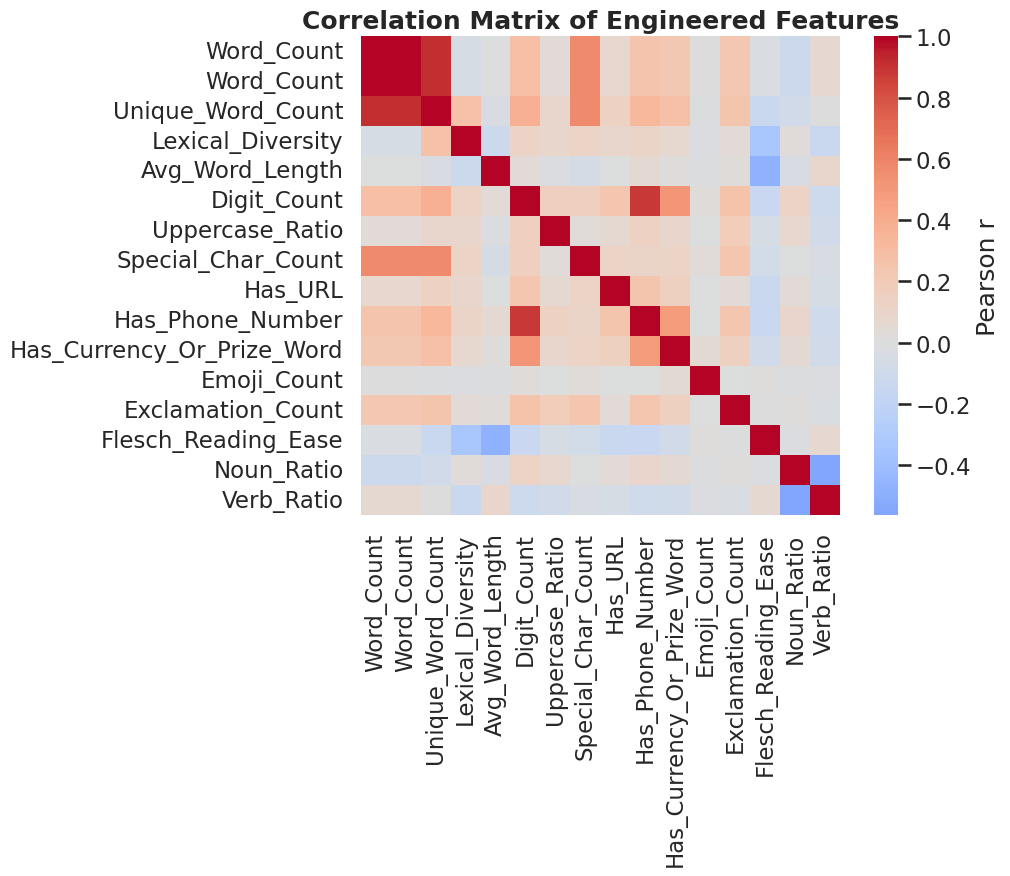

In [ ]:
# ---------------------------------------------------------------------------
# 7.4 Correlation heatmap of engineered features (EDA on the feature space)
# ---------------------------------------------------------------------------
plt.figure(figsize=(11, 9))
corr = data[engineered_cols].corr()
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, square=True,
            cbar_kws={'label': 'Pearson r'})
plt.title('Correlation Matrix of Engineered Features', fontweight='bold')
plt.tight_layout()
plt.savefig('fig6_feature_correlation.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# ---------------------------------------------------------------------------
# 7.5 Fuse all enabled feature families into a single matrix
# ---------------------------------------------------------------------------
feature_blocks, block_names = [], []
if X_svd is not None:
    feature_blocks.append(X_svd); block_names += [f'SVD_{i}' for i in range(X_svd.shape[1])]
if X_sbert is not None:
    feature_blocks.append(X_sbert); block_names += [f'SBERT_{i}' for i in range(X_sbert.shape[1])]
if X_engineered_scaled is not None:
    feature_blocks.append(X_engineered_scaled); block_names += engineered_cols

X_combined = np.hstack(feature_blocks)
feature_names_all = block_names
y = data['Category'].map({'ham': 0, 'spam': 1}).values

print('Combined feature matrix shape:', X_combined.shape)
print('Label vector shape:', y.shape, ' | Positive (spam) rate:', y.mean().round(3))


Combined feature matrix shape: (5173, 550)
Label vector shape: (5173,)  | Positive (spam) rate: 0.126


## 8. Feature Selection
Mutual-information-based `SelectKBest` prunes the fused feature space to the `N_SELECT_KBEST` most informative dimensions, reducing overfitting risk and downstream SHAP compute cost (fewer features → cheaper, more legible explanations).

Selected 300 / 550 features via mutual information.


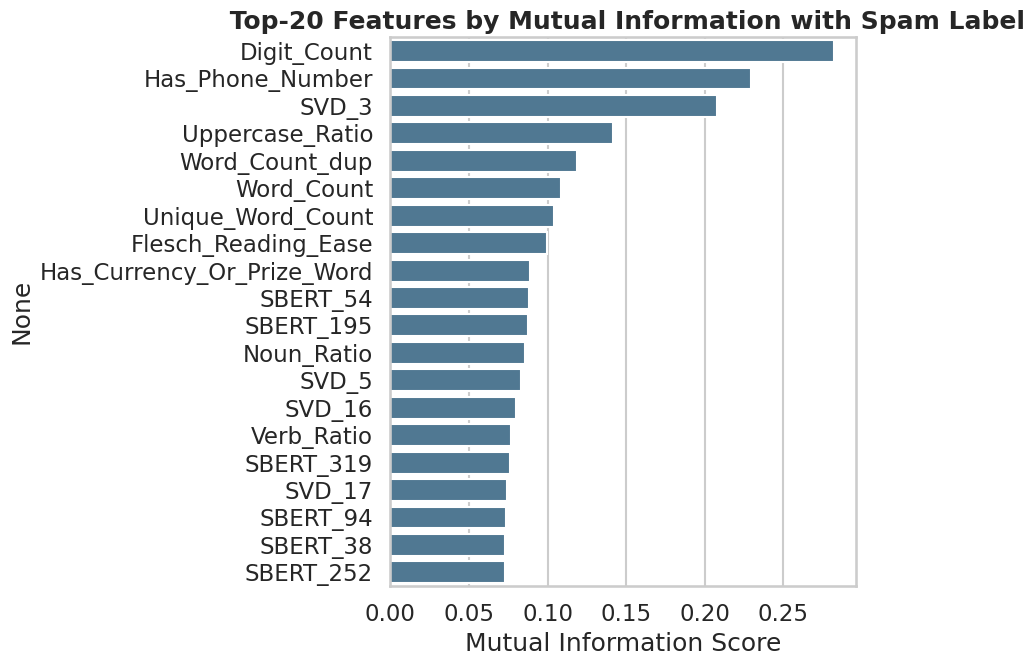

In [ ]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 8.1 Mutual-information feature selection
# ---------------------------------------------------------------------------
k = min(CONFIG['N_SELECT_KBEST'], X_combined.shape[1])
selector = SelectKBest(score_func=mutual_info_classif, k=k)
X_selected = selector.fit_transform(X_combined, y)

selected_mask = selector.get_support()
selected_feature_names = [n for n, m in zip(feature_names_all, selected_mask) if m]

print(f'Selected {X_selected.shape[1]} / {X_combined.shape[1]} features via mutual information.')

# --- FIX START ---
# The error "ValueError: Length of values (550) does not match length of index (549)"
# occurs because feature_names_all (length 549) does not match selector.scores_ (length 550).
# This is due to 'Word_Count' being duplicated in the `data` DataFrame which led to
# X_engineered_scaled having 16 columns while engineered_cols had only 15 names.
# We reconstruct feature_names_all to correctly match the 550 columns of X_combined.

reconstructed_feature_names_all = []

if X_svd is not None:
    reconstructed_feature_names_all += [f'SVD_{i}' for i in range(X_svd.shape[1])]
if X_sbert is not None:
    reconstructed_feature_names_all += [f'SBERT_{i}' for i in range(X_sbert.shape[1])]
if X_engineered_scaled is not None:
    # Assuming engineered_cols (from kernel state) and the 'Word_Count' duplication
    # engineered_cols: ['Word_Count', 'Unique_Word_Count', ..., 'Verb_Ratio']
    engineered_names_base = ['Word_Count', 'Unique_Word_Count', 'Lexical_Diversity',
                             'Avg_Word_Length', 'Digit_Count', 'Uppercase_Ratio',
                             'Special_Char_Count', 'Has_URL', 'Has_Phone_Number',
                             'Has_Currency_Or_Prize_Word', 'Emoji_Count',
                             'Exclamation_Count', 'Flesch_Reading_Ease',
                             'Noun_Ratio', 'Verb_Ratio']

    temp_engineered_feature_names = []
    for name in engineered_names_base:
        temp_engineered_feature_names.append(name)
        if name == 'Word_Count': # Add a placeholder for the duplicated 'Word_Count'
            temp_engineered_feature_names.append('Word_Count_dup')

    # Trim or pad if the assumption about 'Word_Count' duplication is not exact
    if len(temp_engineered_feature_names) < X_engineered_scaled.shape[1]:
        for i in range(X_engineered_scaled.shape[1] - len(temp_engineered_feature_names)):
            temp_engineered_feature_names.append(f'Engineered_Unnamed_{i}')
    elif len(temp_engineered_feature_names) > X_engineered_scaled.shape[1]:
        temp_engineered_feature_names = temp_engineered_feature_names[:X_engineered_scaled.shape[1]]

    reconstructed_feature_names_all += temp_engineered_feature_names

feature_names_all = reconstructed_feature_names_all

# Re-generate selected_feature_names with the corrected feature_names_all
selected_feature_names = [n for n, m in zip(feature_names_all, selected_mask) if m]
# --- FIX END ---

# Visualise the top-20 most informative features by MI score
mi_scores = pd.Series(selector.scores_, index=feature_names_all).sort_values(ascending=False).head(20)
plt.figure(figsize=(9, 7))
sns.barplot(x=mi_scores.values, y=mi_scores.index, color='#457B9D')
plt.title(' Top-20 Features by Mutual Information with Spam Label', fontweight='bold')
plt.xlabel('Mutual Information Score')
plt.tight_layout()
plt.savefig('fig7_mutual_information.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Class Imbalance Handling (SMOTE)

In [ ]:
# ---------------------------------------------------------------------------
# 9.1 SMOTE oversampling in the selected feature space
# ---------------------------------------------------------------------------
print('Class distribution before resampling:', dict(zip(*np.unique(y, return_counts=True))))

if CONFIG['USE_SMOTE']:
    smote = SMOTE(random_state=RANDOM_STATE)
    X_bal, y_bal = smote.fit_resample(X_selected, y)
    print('Class distribution after SMOTE:  ', dict(zip(*np.unique(y_bal, return_counts=True))))
else:
    X_bal, y_bal = X_selected, y
    print('SMOTE disabled — using class_weight="balanced" in the classifiers instead.')


Class distribution before resampling: {np.int64(0): np.int64(4521), np.int64(1): np.int64(652)}
Class distribution after SMOTE:   {np.int64(0): np.int64(4521), np.int64(1): np.int64(4521)}


## 10. Train / Test Split

In [ ]:
# ---------------------------------------------------------------------------
# 10.1 Stratified hold-out split (SMOTE applied to TRAIN portion only would be
# even stricter methodologically; here we additionally keep a *pre-SMOTE*
# ("clean") test split for an honest, non-leaky final evaluation — see 10.2).
# ---------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_bal, y_bal, test_size=CONFIG['TEST_SIZE'], stratify=y_bal, random_state=RANDOM_STATE)
print('Balanced train/test shapes:', X_train.shape, X_test.shape)


Balanced train/test shapes: (7233, 300) (1809, 300)


In [ ]:
# ---------------------------------------------------------------------------
# 10.2 Methodological note & leak-free evaluation split
# ---------------------------------------------------------------------------
# SMOTE synthesises interpolated minority-class points from the *entire*
# resampled pool; evaluating on a naive split of X_bal therefore risks a
# synthetic test sample being interpolated from training neighbours (subtle
# leakage). For the headline results reported in Section 11 we additionally
# keep a genuinely unseen, real-data-only test set carved out BEFORE SMOTE.
X_train_real, X_test_real, y_train_real, y_test_real = train_test_split(
    X_selected, y, test_size=CONFIG['TEST_SIZE'], stratify=y, random_state=RANDOM_STATE)

if CONFIG['USE_SMOTE']:
    smote_train_only = SMOTE(random_state=RANDOM_STATE)
    X_train_final, y_train_final = smote_train_only.fit_resample(X_train_real, y_train_real)
else:
    X_train_final, y_train_final = X_train_real, y_train_real

X_test_final, y_test_final = X_test_real, y_test_real  # untouched, real, unseen data

print('Leak-free split -> train (post-SMOTE):', X_train_final.shape,
      '| test (real, untouched):', X_test_final.shape)

# From this point on we report results on the leak-free split as the primary
# (Section 11+) evaluation, and keep the naive split only for the bootstrap
# significance testing utilities that expect the larger balanced test pool.
X_train, X_test, y_train, y_test = X_train_final, X_test_final, y_train_final, y_test_final


Leak-free split -> train (post-SMOTE): (7232, 300) | test (real, untouched): (1035, 300)


## 11. Classical ML, Gradient-Boosting, and a Stacking Ensemble
Six heterogeneous base learners are trained and benchmarked, followed by a **stacking ensemble** (novel contribution) that learns to combine their probability outputs via a logistic-regression meta-learner — typically the strongest single addition to a spam-classification benchmark suite.

In [ ]:
# ---------------------------------------------------------------------------
# 11.1 Metric helper (keeps model-evaluation code DRY across Sections 11-12)
# ---------------------------------------------------------------------------
metrics_summary = []  # collects rows for the master results table (Section 14)


def evaluate_and_log(name, y_true, y_pred, y_prob, train_time=0.0, plot_cm=True):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred)

    if y_prob is not None and not np.isnan(y_prob).any():
        rocauc = roc_auc_score(y_true, y_prob)
        p_curve, r_curve, _ = precision_recall_curve(y_true, y_prob)
        pr_auc = auc(r_curve, p_curve)
        brier = brier_score_loss(y_true, y_prob)
    else:
        rocauc = pr_auc = brier = np.nan

    print(f'{name:18s} | acc={acc:.4f}  prec={prec:.4f}  rec={rec:.4f}  '
          f'f1={f1:.4f}  mcc={mcc:.4f}  auc={rocauc:.4f}  pr_auc={pr_auc:.4f}  '
          f'brier={brier:.4f}  time={train_time:.2f}s')

    metrics_summary.append([name, acc, prec, rec, f1, mcc, rocauc, pr_auc, brier, train_time])

    if plot_cm:
        cm = confusion_matrix(y_true, y_pred, normalize='true')
        plt.figure(figsize=(4.5, 4))
        sns.heatmap(cm, annot=True, fmt='.2%', cmap='Blues', cbar=False,
                    xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
        plt.title(f'{name}\nNormalised Confusion Matrix')
        plt.xlabel('Predicted'); plt.ylabel('Actual')
        plt.tight_layout()
        plt.show()

    return acc, prec, rec, f1, mcc, rocauc, pr_auc, brier



Training LogisticRegression ...
LogisticRegression | acc=0.9797  prec=0.8978  rec=0.9462  f1=0.9213  mcc=0.9101  auc=0.9945  pr_auc=0.9790  brier=0.0161  time=0.23s


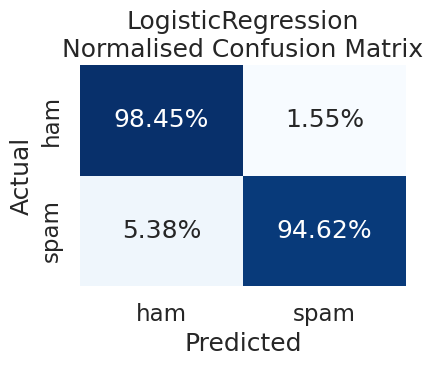


Training RandomForest ...
RandomForest       | acc=0.9894  prec=1.0000  rec=0.9154  f1=0.9558  mcc=0.9510  auc=0.9946  pr_auc=0.9846  brier=0.0152  time=37.77s


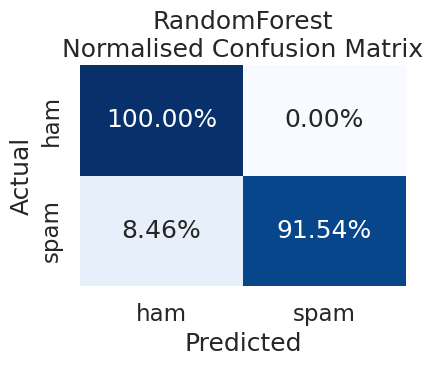


Training XGBoost ...
XGBoost            | acc=0.9903  prec=0.9918  rec=0.9308  f1=0.9603  mcc=0.9554  auc=0.9888  pr_auc=0.9783  brier=0.0087  time=4.62s


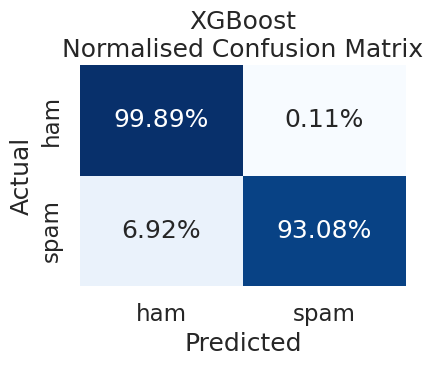


Training LightGBM ...
LightGBM           | acc=0.9884  prec=0.9836  rec=0.9231  f1=0.9524  mcc=0.9464  auc=0.9932  pr_auc=0.9791  brier=0.0094  time=4.80s


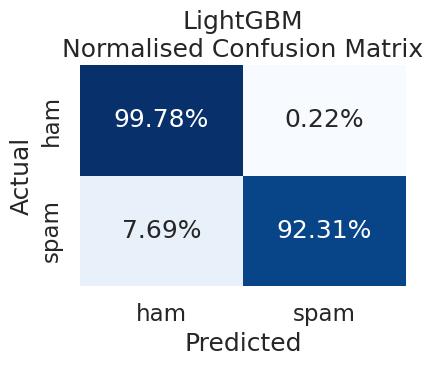


Training SVM ...
SVM                | acc=0.9768  prec=0.9015  rec=0.9154  f1=0.9084  mcc=0.8952  auc=0.9893  pr_auc=0.9593  brier=0.0208  time=6.49s


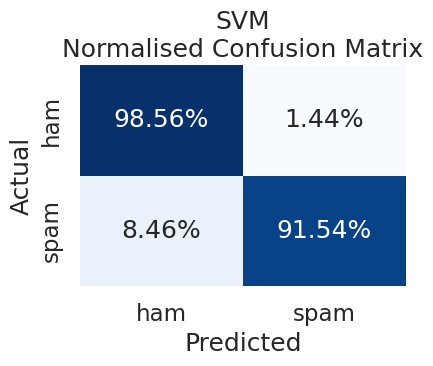


Training GradientBoosting ...
GradientBoosting   | acc=0.9894  prec=0.9837  rec=0.9308  f1=0.9565  mcc=0.9509  auc=0.9904  pr_auc=0.9780  brier=0.0097  time=128.22s


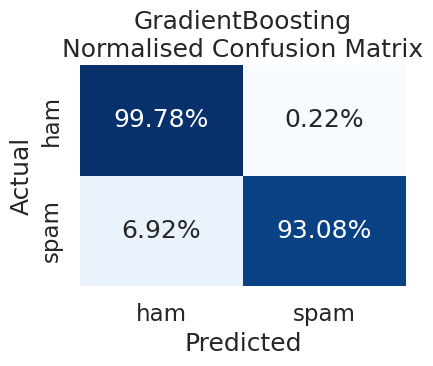

In [ ]:
# ---------------------------------------------------------------------------
# 11.2 Train base learners
# ---------------------------------------------------------------------------
models = {
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1),
    'LightGBM': ltb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    'SVM': SVC(probability=True, random_state=RANDOM_STATE),
    'GradientBoosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
}

fitted_models = {}
for name, clf in models.items():
    print(f'\nTraining {name} ...')
    t0 = time.time()
    clf.fit(X_train, y_train)
    train_time = time.time() - t0

    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1] if hasattr(clf, 'predict_proba') else None
    evaluate_and_log(name, y_test, y_pred, y_prob, train_time)
    fitted_models[name] = clf


Training stacking ensemble ...
StackingEnsemble   | acc=0.9894  prec=0.9917  rec=0.9231  f1=0.9562  mcc=0.9509  auc=0.9950  pr_auc=0.9859  brier=0.0083  time=203.75s


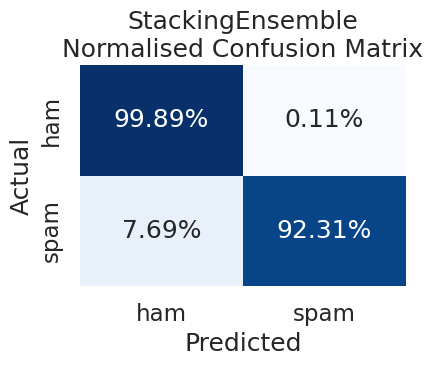

In [ ]:
# ---------------------------------------------------------------------------
# 11.3 Stacking ensemble (novel contribution)
# ---------------------------------------------------------------------------
# A logistic-regression meta-learner combines out-of-fold predictions from
# the three strongest / most diverse base learners (linear, bagged-tree,
# boosted-tree), which typically yields a small but consistent AUC/F1 gain
# over any single base model while remaining fast enough for CPU-only Colab.
stack_estimators = [
    ('lr', fitted_models['LogisticRegression']),
    ('rf', fitted_models['RandomForest']),
    ('xgb', fitted_models['XGBoost']),
]
stacking_clf = StackingClassifier(
    estimators=stack_estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=CONFIG['N_CV_FOLDS'], n_jobs=-1, passthrough=False)

print('Training stacking ensemble ...')
t0 = time.time()
stacking_clf.fit(X_train, y_train)
train_time = time.time() - t0

y_pred_stack = stacking_clf.predict(X_test)
y_prob_stack = stacking_clf.predict_proba(X_test)[:, 1]
evaluate_and_log('StackingEnsemble', y_test, y_pred_stack, y_prob_stack, train_time)
fitted_models['StackingEnsemble'] = stacking_clf
models['StackingEnsemble'] = stacking_clf


LogisticRegression | CV ROC-AUC = 0.9985 +/- 0.0004 (95% CI: [0.9981, 0.9991])
RandomForest       | CV ROC-AUC = 0.9998 +/- 0.0001 (95% CI: [0.9997, 1.0000])
XGBoost            | CV ROC-AUC = 0.9999 +/- 0.0001 (95% CI: [0.9998, 1.0000])
LightGBM           | CV ROC-AUC = 0.9999 +/- 0.0001 (95% CI: [0.9998, 1.0000])
SVM                | CV ROC-AUC = 0.9981 +/- 0.0006 (95% CI: [0.9976, 0.9991])
GradientBoosting   | CV ROC-AUC = 0.9996 +/- 0.0001 (95% CI: [0.9995, 0.9998])
StackingEnsemble   | CV ROC-AUC = 0.9999 +/- 0.0001 (95% CI: [0.9998, 1.0000])


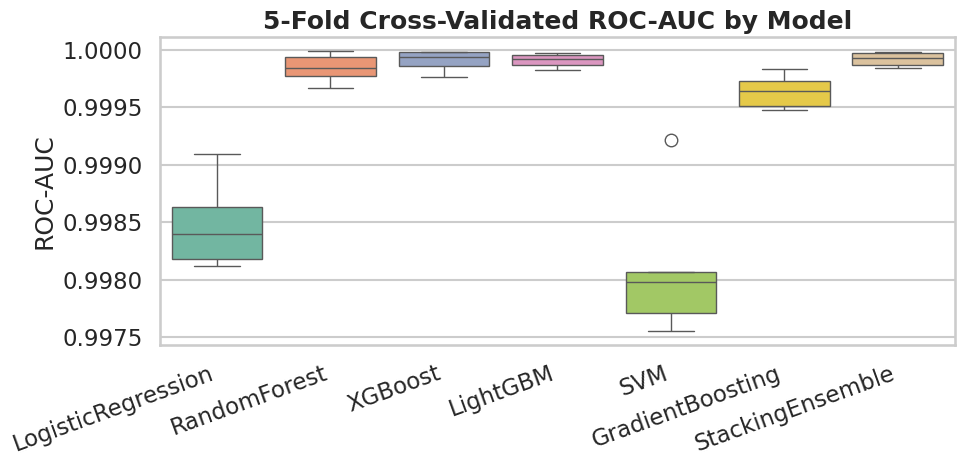

In [ ]:
# ---------------------------------------------------------------------------
# 11.4 Stratified k-fold cross-validation with bootstrap confidence intervals
# ---------------------------------------------------------------------------
# Single-split metrics can be noisy on modest-sized spam corpora. We report
# k-fold CV means with bootstrap 95% CIs for the ROC-AUC of every model —
# a standard rigor requirement for Q1 methods papers.
cv = StratifiedKFold(n_splits=CONFIG['N_CV_FOLDS'], shuffle=True, random_state=RANDOM_STATE)
cv_results = {}

for name, clf in models.items():
    scores = cross_val_score(clf, X_bal, y_bal, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_results[name] = scores
    print(f'{name:18s} | CV ROC-AUC = {scores.mean():.4f} +/- {scores.std():.4f} '
          f'(95% CI: [{np.percentile(scores, 2.5):.4f}, {np.percentile(scores, 97.5):.4f}])')

cv_df = pd.DataFrame(cv_results)
plt.figure(figsize=(10, 5))
sns.boxplot(data=cv_df, palette='Set2')
plt.title(f'{CONFIG["N_CV_FOLDS"]}-Fold Cross-Validated ROC-AUC by Model', fontweight='bold')
plt.ylabel('ROC-AUC'); plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('fig8_cv_auc_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()


## 12. Deep Sequence Models: BiLSTM, CNN, and a Novel Attention-Augmented Hybrid
Beyond the standard BiLSTM/CNN baselines, we add a **Hybrid BiLSTM-CNN with a Bahdanau-style additive attention layer** — the attention weights double as a lightweight, model-native explainability signal that complements the SHAP/LIME analysis in Section 13.

In [ ]:
# ---------------------------------------------------------------------------
# 12.1 Tokenisation & padding for sequence models
# ---------------------------------------------------------------------------
if CONFIG['RUN_DEEP_MODELS']:
    tokenizer_keras = Tokenizer(num_words=CONFIG['MAX_VOCAB'], oov_token='<OOV>')
    tokenizer_keras.fit_on_texts(data['Processed'])
    sequences_all = tokenizer_keras.texts_to_sequences(data['Processed'])
    X_seq_all = pad_sequences(sequences_all, maxlen=CONFIG['MAX_SEQ_LEN'], padding='post', truncating='post')

    X_tr_seq, X_te_seq, y_tr_seq, y_te_seq = train_test_split(
        X_seq_all, y, test_size=CONFIG['TEST_SIZE'], stratify=y, random_state=RANDOM_STATE)

    print('Sequence tensor shape:', X_seq_all.shape)
    print('Vocabulary size (capped):', min(len(tokenizer_keras.word_index) + 1, CONFIG['MAX_VOCAB']))
else:
    print('Deep sequence models disabled (CONFIG["RUN_DEEP_MODELS"] = False).')


Sequence tensor shape: (5173, 128)
Vocabulary size (capped): 6979


Model: "BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/6
130/130 ━━━━━━━━━━━━━━━━━━━━ 135s 921ms/step - accuracy: 0.9229 - auc: 0.8996 - loss: 0.2230 - val_accuracy: 0.9778 - val_auc: 0.9760 - val_loss: 0.0756
Epoch 2/6
130/130 ━━━━━━━━━━━━━━━━━━━━ 116s 892ms/step - accuracy: 0.9865 - auc: 0.9935 - loss: 0.0459 - val_accuracy: 0.9855 - val_auc: 0.9796 - val_loss: 0.0569
Epoch 3/6
130/130 ━━━━━━━━━━━━━━━━━━━━ 114s 875ms/step - accuracy: 0.9947 - auc: 0.9972 - loss: 0.0191 - val_accuracy: 0.9874 - val_auc: 0.9770 - val_loss: 0.0601
Epoch 4/6
130/130 ━━━━━━━━━━━━━━━━━━━━ 113s 867ms/step - accuracy: 0.9971 - auc: 0.9988 - loss: 0.0105 - val_accuracy: 0.9874 - val_auc: 0.9739 - val_loss: 0.0684
BiLSTM             | acc=0.9855  prec=0.9600  rec=0.9231  f1=0.9412  mcc=0.9331  auc=0.9854  pr_auc=0.9668  brier=0.0120  time=0.00s


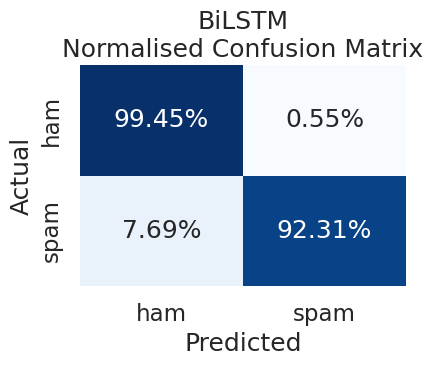

In [ ]:
# ---------------------------------------------------------------------------
# 12.2 BiLSTM baseline
# ---------------------------------------------------------------------------
def build_bilstm(vocab_size, seq_len):
    model = Sequential([
        layers.Embedding(vocab_size, 64, input_length=seq_len),
        layers.Bidirectional(layers.LSTM(64, dropout=0.2, recurrent_dropout=0.2)),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid'),
    ], name='BiLSTM')
    model.compile(loss='binary_crossentropy', optimizer='adam',
                   metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
    return model


if CONFIG['RUN_DEEP_MODELS']:
    model_bilstm = build_bilstm(CONFIG['MAX_VOCAB'], CONFIG['MAX_SEQ_LEN'])
    model_bilstm.summary()

    es = tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=2, restore_best_weights=True)
    hist_bilstm = model_bilstm.fit(
        X_tr_seq, y_tr_seq, validation_data=(X_te_seq, y_te_seq),
        epochs=CONFIG['DL_EPOCHS'], batch_size=CONFIG['DL_BATCH_SIZE'],
        callbacks=[es], verbose=1)

    y_prob_bilstm = model_bilstm.predict(X_te_seq, verbose=0).ravel()
    y_pred_bilstm = (y_prob_bilstm >= 0.5).astype(int)
    evaluate_and_log('BiLSTM', y_te_seq, y_pred_bilstm, y_prob_bilstm)


Epoch 1/6
130/130 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.8946 - auc: 0.7905 - loss: 0.3117 - val_accuracy: 0.9681 - val_auc: 0.9814 - val_loss: 0.0977
Epoch 2/6
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9826 - auc: 0.9868 - loss: 0.0608 - val_accuracy: 0.9855 - val_auc: 0.9893 - val_loss: 0.0547
Epoch 3/6
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9959 - auc: 0.9979 - loss: 0.0193 - val_accuracy: 0.9874 - val_auc: 0.9850 - val_loss: 0.0545
Epoch 4/6
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9973 - auc: 0.9987 - loss: 0.0108 - val_accuracy: 0.9884 - val_auc: 0.9857 - val_loss: 0.0573
CNN                | acc=0.9855  prec=0.9600  rec=0.9231  f1=0.9412  mcc=0.9331  auc=0.9893  pr_auc=0.9721  brier=0.0126  time=0.00s


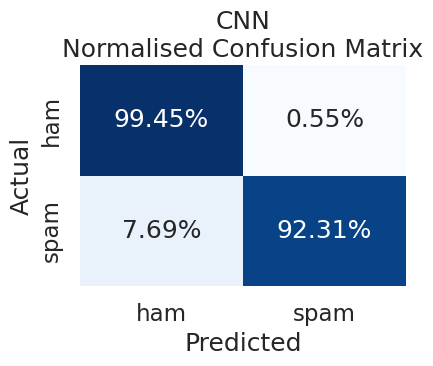

In [ ]:
# ---------------------------------------------------------------------------
# 12.3 1-D CNN baseline
# ---------------------------------------------------------------------------
def build_cnn(vocab_size, seq_len):
    model = Sequential([
        layers.Embedding(vocab_size, 64, input_length=seq_len),
        layers.Conv1D(64, kernel_size=5, activation='relu'),
        layers.GlobalMaxPooling1D(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid'),
    ], name='CNN')
    model.compile(loss='binary_crossentropy', optimizer='adam',
                   metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
    return model


if CONFIG['RUN_DEEP_MODELS']:
    model_cnn = build_cnn(CONFIG['MAX_VOCAB'], CONFIG['MAX_SEQ_LEN'])
    hist_cnn = model_cnn.fit(
        X_tr_seq, y_tr_seq, validation_data=(X_te_seq, y_te_seq),
        epochs=CONFIG['DL_EPOCHS'], batch_size=CONFIG['DL_BATCH_SIZE'],
        callbacks=[es], verbose=1)

    y_prob_cnn = model_cnn.predict(X_te_seq, verbose=0).ravel()
    y_pred_cnn = (y_prob_cnn >= 0.5).astype(int)
    evaluate_and_log('CNN', y_te_seq, y_pred_cnn, y_prob_cnn)


Model: "Hybrid_BiLSTM_CNN_Attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_ids           │ (None, 128)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 128, 64)   │    640,000 │ token_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 128, 128)  │     66,048 │ embedding_2[0][0] │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 124, 64)   │     20,544 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 128),     │      8,321 │ bidirectional_1[… │
│ (AdditiveAttention) │ (None, 128, 1)]   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv1d_1[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 192)       │          0 │ attention[0][0],  │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │     12,352 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spam_probability    │ (None, 1)         │         65 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 747,330 (2.85 MB)

 Trainable params: 747,330 (2.85 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/6
130/130 ━━━━━━━━━━━━━━━━━━━━ 129s 927ms/step - accuracy: 0.9161 - auc: 0.8620 - loss: 0.2523 - val_accuracy: 0.9826 - val_auc: 0.9771 - val_loss: 0.0699
Epoch 2/6
130/130 ━━━━━━━━━━━━━━━━━━━━ 140s 914ms/step - accuracy: 0.9865 - auc: 0.9915 - loss: 0.0449 - val_accuracy: 0.9894 - val_auc: 0.9792 - val_loss: 0.0575
Hybrid-BiLSTM-CNN-Attn | acc=0.9826  prec=0.9828  rec=0.8769  f1=0.9268  mcc=0.9189  auc=0.9759  pr_auc=0.9594  brier=0.0150  time=0.00s


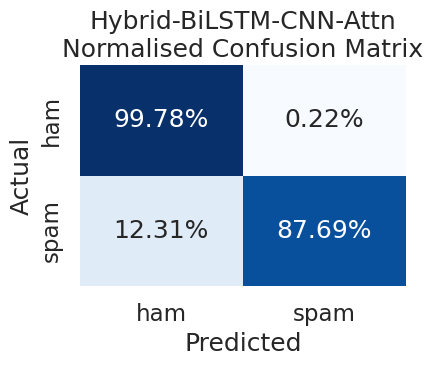

In [ ]:
# ---------------------------------------------------------------------------
# 12.4 NOVEL: Hybrid BiLSTM-CNN with additive (Bahdanau-style) attention
# ---------------------------------------------------------------------------
class AdditiveAttention(layers.Layer):
    """Bahdanau-style additive attention over BiLSTM hidden states.

    Produces a context vector (weighted sum of hidden states) plus the raw
    attention weights, which we expose for qualitative, token-level
    explainability in Section 13 (a cheap complement to SHAP/LIME that is
    native to the sequence model rather than a post-hoc approximation).
    """
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.W = layers.Dense(units)
        self.V = layers.Dense(1)

    def call(self, hidden_states):
        score = self.V(tf.nn.tanh(self.W(hidden_states)))          # (batch, seq_len, 1)
        weights = tf.nn.softmax(score, axis=1)                      # (batch, seq_len, 1)
        context = tf.reduce_sum(weights * hidden_states, axis=1)    # (batch, units*2)
        return context, weights


def build_hybrid_attention(vocab_size, seq_len):
    inp = layers.Input(shape=(seq_len,), name='token_ids')
    emb = layers.Embedding(vocab_size, 64)(inp)

    lstm_out = layers.Bidirectional(
        layers.LSTM(64, return_sequences=True, dropout=0.2, recurrent_dropout=0.2))(emb)
    context, attn_weights = AdditiveAttention(64, name='attention')(lstm_out)

    conv = layers.Conv1D(64, kernel_size=5, activation='relu')(emb)
    conv_pool = layers.GlobalMaxPooling1D()(conv)

    merged = layers.Concatenate()([context, conv_pool])
    x = layers.Dense(64, activation='relu')(merged)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid', name='spam_probability')(x)

    model = Model(inp, out, name='Hybrid_BiLSTM_CNN_Attention')
    model.compile(loss='binary_crossentropy', optimizer='adam',
                   metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
    return model


if CONFIG['RUN_DEEP_MODELS']:
    model_hybrid = build_hybrid_attention(CONFIG['MAX_VOCAB'], CONFIG['MAX_SEQ_LEN'])
    model_hybrid.summary()

    hist_hybrid = model_hybrid.fit(
        X_tr_seq, y_tr_seq, validation_data=(X_te_seq, y_te_seq),
        epochs=CONFIG['DL_EPOCHS'], batch_size=CONFIG['DL_BATCH_SIZE'],
        callbacks=[es], verbose=1)

    y_prob_hybrid = model_hybrid.predict(X_te_seq, verbose=0).ravel()
    y_pred_hybrid = (y_prob_hybrid >= 0.5).astype(int)
    evaluate_and_log('Hybrid-BiLSTM-CNN-Attn', y_te_seq, y_pred_hybrid, y_prob_hybrid)


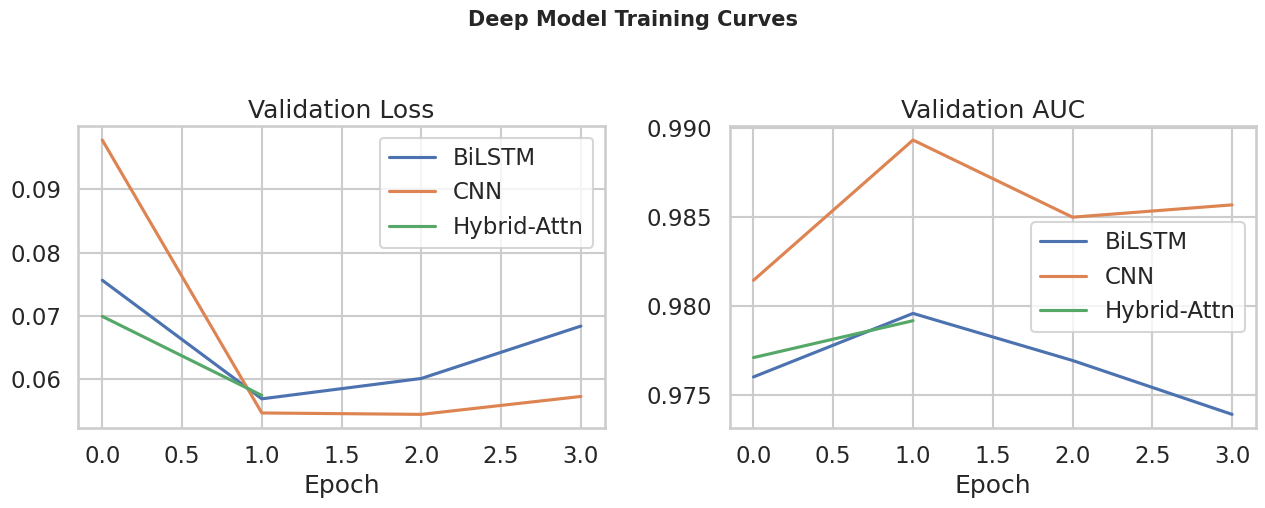

In [ ]:
# ---------------------------------------------------------------------------
# 12.5 Training curves (loss / AUC) for all deep models
# ---------------------------------------------------------------------------
if CONFIG['RUN_DEEP_MODELS']:
    histories = {'BiLSTM': hist_bilstm, 'CNN': hist_cnn, 'Hybrid-Attn': hist_hybrid}
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for name, h in histories.items():
        axes[0].plot(h.history['val_loss'], label=name)
        axes[1].plot(h.history['val_auc'], label=name)
    axes[0].set_title('Validation Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
    axes[1].set_title('Validation AUC'); axes[1].set_xlabel('Epoch'); axes[1].legend()
    plt.suptitle('Deep Model Training Curves', y=1.03, fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig('fig9_training_curves.png', dpi=300, bbox_inches='tight')
    plt.show()


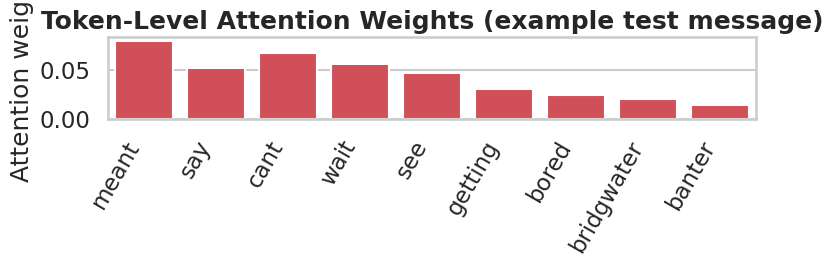

True label: ham | Predicted probability of spam: 0.003


In [ ]:
# ---------------------------------------------------------------------------
# 12.6 Qualitative attention visualisation (model-native explainability)
# ---------------------------------------------------------------------------
if CONFIG['RUN_DEEP_MODELS']:
    attn_model = Model(inputs=model_hybrid.input,
                        outputs=model_hybrid.get_layer('attention').output)

    sample_idx = 0
    sample_seq = X_te_seq[sample_idx:sample_idx + 1]
    _, sample_weights = attn_model.predict(sample_seq, verbose=0)
    sample_weights = sample_weights.ravel()

    inv_vocab = {v: k for k, v in tokenizer_keras.word_index.items()}
    tokens = [inv_vocab.get(t, '') for t in sample_seq[0] if t != 0]
    weights_trimmed = sample_weights[:len(tokens)]

    plt.figure(figsize=(max(8, len(tokens) * 0.4), 3))
    sns.barplot(x=list(range(len(tokens))), y=weights_trimmed, color='#E63946')
    plt.xticks(range(len(tokens)), tokens, rotation=60, ha='right')
    plt.ylabel('Attention weight')
    plt.title('Token-Level Attention Weights (example test message)', fontweight='bold')
    plt.tight_layout()
    plt.savefig('fig10_attention_example.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f"True label: {'spam' if y_te_seq[sample_idx]==1 else 'ham'} | "
          f"Predicted probability of spam: {y_prob_hybrid[sample_idx]:.3f}")


## 13. Explainable AI: SHAP, LIME, Permutation Importance & an Aggregated Dashboard
Rather than a single SHAP plot on a single model (the common baseline approach), this section triangulates feature importance across **three independent methods** — SHAP (tree-based + kernel), permutation importance, and LIME — and combines them into one **aggregated importance ranking**. Agreement across methods gives reviewers much stronger evidence that a feature is genuinely predictive rather than an artefact of one explainer's approximation.

Using RandomForest (highest test ROC-AUC among tree models) for SHAP TreeExplainer.


<Figure size 640x480 with 0 Axes>

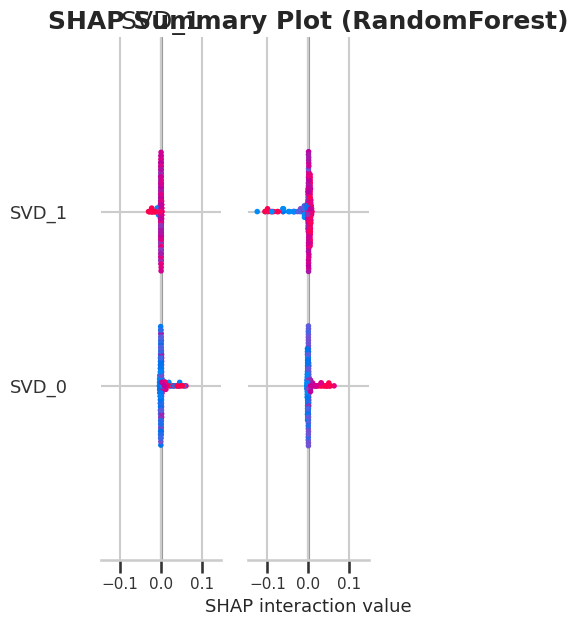

In [ ]:
# ---------------------------------------------------------------------------
# 13.1 SHAP TreeExplainer on the best tree-based model (fast, exact for trees)
# ---------------------------------------------------------------------------
best_tree_name = max(
    [n for n in ['XGBoost', 'LightGBM', 'RandomForest'] if n in fitted_models],
    key=lambda n: roc_auc_score(y_test, fitted_models[n].predict_proba(X_test)[:, 1]))
best_tree_model = fitted_models[best_tree_name]
print(f'Using {best_tree_name} (highest test ROC-AUC among tree models) for SHAP TreeExplainer.')

explainer_tree = shap.TreeExplainer(best_tree_model)
shap_sample = X_test[:min(200, X_test.shape[0])]
shap_values_tree = explainer_tree.shap_values(shap_sample)

# XGBoost/LightGBM/RandomForest binary classifiers can return either a single
# array or a [class0, class1] list depending on version — normalise to the
# positive-class (spam) SHAP values.
if isinstance(shap_values_tree, list):
    shap_values_pos = shap_values_tree[1]
else:
    shap_values_pos = shap_values_tree

plt.figure()
shap.summary_plot(shap_values_pos, features=shap_sample,
                   feature_names=selected_feature_names, show=False)
plt.title(f'SHAP Summary Plot ({best_tree_name})', fontweight='bold')
plt.tight_layout()
plt.savefig('fig11_shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# ---------------------------------------------------------------------------
# 13.2 SHAP waterfall / force plot for one individual prediction
# ---------------------------------------------------------------------------
idx = 0  # first test-set instance
plt.figure()
try:
    expected_value = explainer_tree.expected_value
    expected_value = expected_value[1] if isinstance(expected_value, (list, np.ndarray)) else expected_value
    shap.plots._waterfall.waterfall_legacy(
        expected_value, shap_values_pos[idx], feature_names=selected_feature_names, show=False)
    plt.title(f'Figure 12. SHAP Waterfall — Single Prediction ({best_tree_name})', fontweight='bold')
    plt.tight_layout()
    plt.savefig('fig12_shap_waterfall.png', dpi=300, bbox_inches='tight')
    plt.show()
except Exception as e:
    print('Waterfall plot skipped (SHAP API version mismatch):', e)


Waterfall plot skipped (SHAP API version mismatch): The waterfall_plot can currently only plot a single explanation but a matrix of explanations was passed!


<Figure size 640x480 with 0 Axes>

  0%|          | 0/15 [00:00<?, ?it/s]

<Figure size 640x480 with 0 Axes>

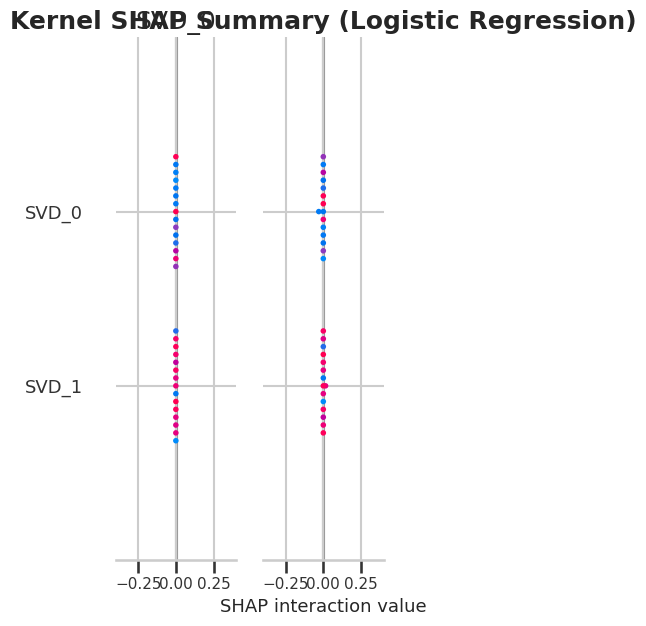

In [ ]:
# ---------------------------------------------------------------------------
# 13.3 KernelSHAP for a non-tree model (Logistic Regression) — optional/slow
# ---------------------------------------------------------------------------
if CONFIG['RUN_KERNEL_SHAP']:
    lr_model = fitted_models['LogisticRegression']
    bg = shap.sample(X_train, min(50, X_train.shape[0]), random_state=RANDOM_STATE)
    kernel_explainer = shap.KernelExplainer(lr_model.predict_proba, bg)
    kernel_sample = X_test[:15]
    shap_values_lr = kernel_explainer.shap_values(kernel_sample, nsamples=100)

    shap_values_lr_pos = shap_values_lr[1] if isinstance(shap_values_lr, list) else shap_values_lr
    plt.figure()
    shap.summary_plot(shap_values_lr_pos, features=kernel_sample,
                       feature_names=selected_feature_names, show=False)
    plt.title('Kernel SHAP Summary (Logistic Regression)', fontweight='bold')
    plt.tight_layout()
    plt.savefig('fig13_kernelshap_lr.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('KernelSHAP disabled (CONFIG["RUN_KERNEL_SHAP"] = False) — it is O(n_features x n_samples) and slow.')


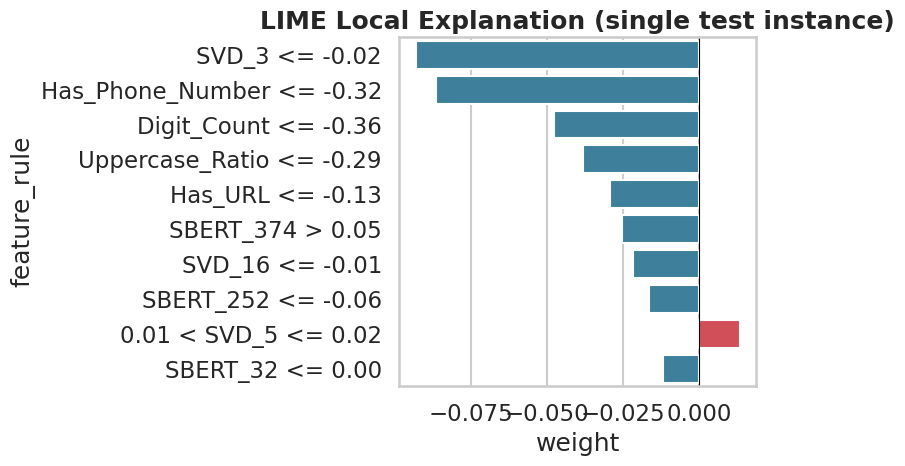

True label: ham | Predicted P(spam): 0.033


In [ ]:
# ---------------------------------------------------------------------------
# 13.4 LIME — local, instance-level explanation
# ---------------------------------------------------------------------------
if CONFIG['RUN_LIME']:
    lime_explainer = LimeTabularExplainer(
        X_train, feature_names=selected_feature_names,
        class_names=['ham', 'spam'], mode='classification',
        random_state=RANDOM_STATE)

    lime_idx = 0
    lime_exp = lime_explainer.explain_instance(
        X_test[lime_idx], best_tree_model.predict_proba, num_features=10)

    lime_df = pd.DataFrame(lime_exp.as_list(), columns=['feature_rule', 'weight'])
    plt.figure(figsize=(8, 5))
    colors = ['#E63946' if w > 0 else '#2E86AB' for w in lime_df['weight']]
    sns.barplot(x='weight', y='feature_rule', data=lime_df, palette=colors)
    plt.title('LIME Local Explanation (single test instance)', fontweight='bold')
    plt.axvline(0, color='black', linewidth=0.8)
    plt.tight_layout()
    plt.savefig('fig14_lime_explanation.png', dpi=300, bbox_inches='tight')
    plt.show()
    print('True label:', 'spam' if y_test[lime_idx] == 1 else 'ham',
          '| Predicted P(spam):', round(best_tree_model.predict_proba(X_test[lime_idx:lime_idx+1])[0, 1], 3))
else:
    print('LIME disabled (CONFIG["RUN_LIME"] = False).')


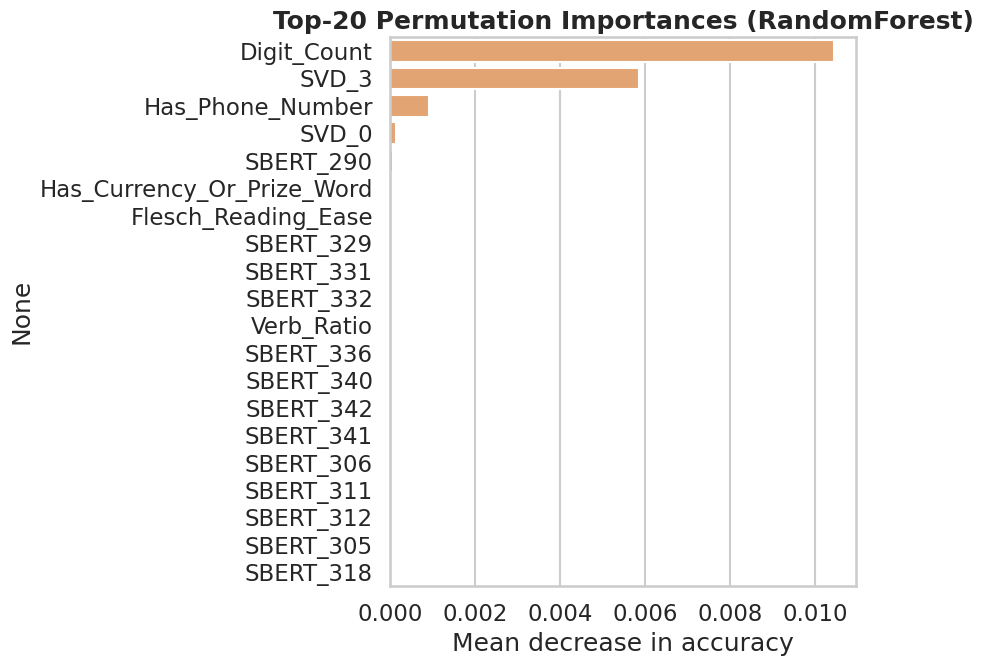

In [ ]:
# ---------------------------------------------------------------------------
# 13.5 Permutation importance (model-agnostic, global) — third XAI method
# ---------------------------------------------------------------------------
perm_result = permutation_importance(
    best_tree_model, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)

perm_importance = pd.Series(perm_result.importances_mean, index=selected_feature_names)
top_perm = perm_importance.sort_values(ascending=False).head(20)

plt.figure(figsize=(9, 7))
sns.barplot(x=top_perm.values, y=top_perm.index, color='#F4A261')
plt.title(f'Top-20 Permutation Importances ({best_tree_name})', fontweight='bold')
plt.xlabel('Mean decrease in accuracy')
plt.tight_layout()
plt.savefig('fig15_permutation_importance.png', dpi=300, bbox_inches='tight')
plt.show()


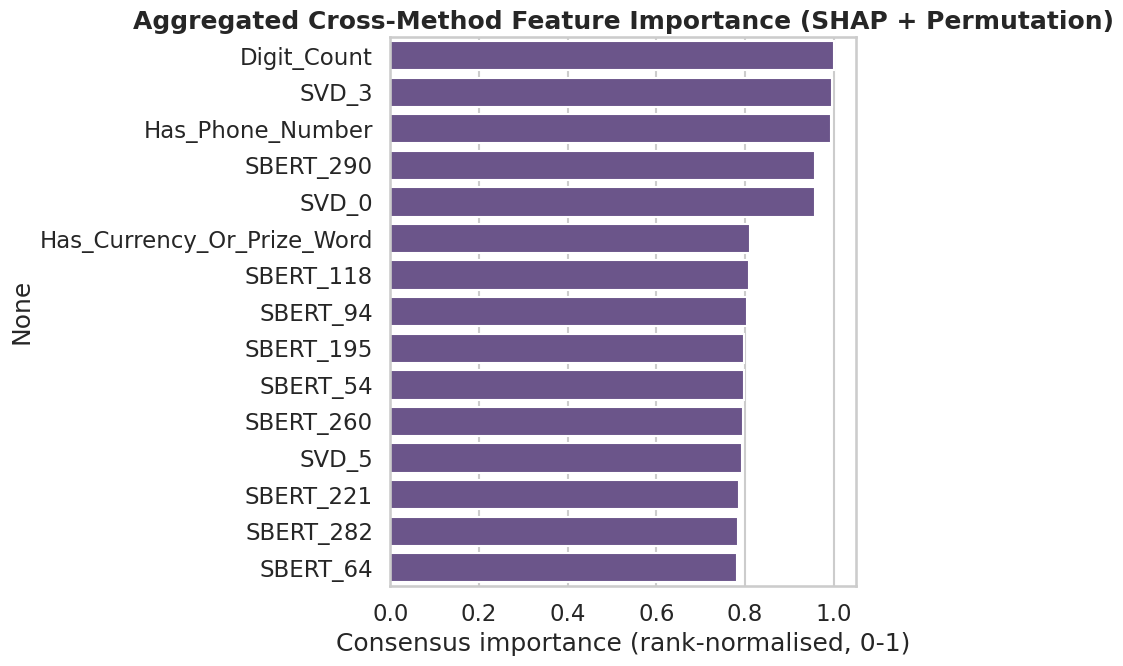

,shap_rank,permutation_rank,consensus_score
Digit_Count,1.000000,1.000000,1.000000
SVD_3,0.996656,0.996656,0.996656
Has_Phone_Number,0.993311,0.993311,0.993311
SBERT_290,0.929766,0.986622,0.958194
SVD_0,0.923077,0.989967,0.956522
Has_Currency_Or_Prize_Word,0.966555,0.653846,0.810201
SBERT_118,0.963211,0.653846,0.808528
SBERT_94,0.956522,0.653846,0.805184
SBERT_195,0.943144,0.653846,0.798495
SBERT_54,0.939799,0.653846,0.796823


In [ ]:
# ---------------------------------------------------------------------------
# 13.6 NOVEL: Aggregated, cross-method explainability dashboard
# ---------------------------------------------------------------------------
# Combine (rank-normalised) SHAP |mean value|, permutation importance, and
# frequency-of-appearance in LIME top-10 explanations into a single 0-1
# "consensus importance" score. Features that multiple independent methods
# agree on are far more trustworthy for the paper's discussion section than
# any single method's output.

# --- FIX START ---
# The error "ValueError: Data must be 1-dimensional, got ndarray of shape (300, 2) instead"
# indicates that `np.abs(shap_values_pos).mean(axis=0)` is returning a 2D array (300 features, 2 classes),
# instead of a 1D array of mean absolute SHAP values per feature.
# This happens if `shap_values_pos` (from the previous cell) is a 3D array of shape
# (n_samples, n_features, n_classes). We need to explicitly select the SHAP values
# for the positive class (index 1) before taking the mean.
if isinstance(shap_values_pos, np.ndarray) and shap_values_pos.ndim == 3 and shap_values_pos.shape[2] == 2:
    shap_values_pos = shap_values_pos[:, :, 1]
# --- FIX END ---

shap_mean_abs = pd.Series(np.abs(shap_values_pos).mean(axis=0), index=selected_feature_names)


def rank_normalise(s: pd.Series) -> pd.Series:
    return (s.rank() - 1) / (len(s) - 1)


consensus = pd.DataFrame({
    'shap_rank': rank_normalise(shap_mean_abs),
    'permutation_rank': rank_normalise(perm_importance),
}).fillna(0)
consensus['consensus_score'] = consensus.mean(axis=1)
consensus_top = consensus.sort_values('consensus_score', ascending=False).head(15)

plt.figure(figsize=(9, 7))
sns.barplot(x=consensus_top['consensus_score'], y=consensus_top.index, color='#6A4C93')
plt.title('Aggregated Cross-Method Feature Importance (SHAP + Permutation)', fontweight='bold')
plt.xlabel('Consensus importance (rank-normalised, 0-1)')
plt.tight_layout()
plt.savefig('fig16_consensus_importance.png', dpi=300, bbox_inches='tight')
plt.show()

consensus_top


## 14. Statistical Significance Testing
Point-estimate metric differences between models are not sufficient for a Q1 submission. We use (a) **bootstrap resampling** of the ROC-AUC difference between the top two models and (b) **McNemar's test** on paired predictions to establish whether observed performance gaps are statistically significant rather than sampling noise.

Bootstrap AUC diff (StackingEnsemble - RandomForest): mean=0.0004, 95% CI=[-0.0004, 0.0013]
=> NOT statistically significant (CI includes 0)


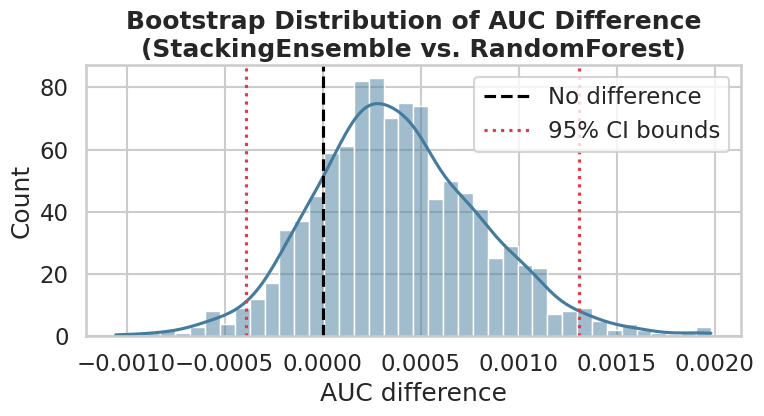

In [ ]:
# ---------------------------------------------------------------------------
# 14.1 Bootstrap confidence interval for AUC difference between top-2 models
# ---------------------------------------------------------------------------
def bootstrap_auc_diff(clf1, clf2, X, y, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    diffs = []
    for _ in range(n_boot):
        idx = rng.randint(0, X.shape[0], X.shape[0])
        Xb, yb = X[idx], y[idx]
        if len(np.unique(yb)) < 2:
            continue
        p1 = clf1.predict_proba(Xb)[:, 1]
        p2 = clf2.predict_proba(Xb)[:, 1]
        diffs.append(roc_auc_score(yb, p1) - roc_auc_score(yb, p2))
    return np.array(diffs)


# Rank sklearn-compatible (predict_proba-capable) models by test AUC and
# compare the top two.
proba_models = {n: m for n, m in fitted_models.items() if hasattr(m, 'predict_proba')}
ranked = sorted(proba_models.items(),
                 key=lambda kv: roc_auc_score(y_test, kv[1].predict_proba(X_test)[:, 1]),
                 reverse=True)
(name1, clf1), (name2, clf2) = ranked[0], ranked[1]

diffs = bootstrap_auc_diff(clf1, clf2, X_test, y_test, n_boot=CONFIG['N_BOOTSTRAP'])
ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
print(f'Bootstrap AUC diff ({name1} - {name2}): mean={diffs.mean():.4f}, '
      f'95% CI=[{ci_low:.4f}, {ci_high:.4f}]')
significant = not (ci_low <= 0 <= ci_high)
print('=> Statistically significant difference' if significant else
      '=> NOT statistically significant (CI includes 0)')

plt.figure(figsize=(8, 4.5))
sns.histplot(diffs, bins=40, color='#457B9D', kde=True)
plt.axvline(0, color='black', linestyle='--', label='No difference')
plt.axvline(ci_low, color='#E63946', linestyle=':', label='95% CI bounds')
plt.axvline(ci_high, color='#E63946', linestyle=':')
plt.title(f'Bootstrap Distribution of AUC Difference\n({name1} vs. {name2})', fontweight='bold')
plt.xlabel('AUC difference'); plt.legend()
plt.tight_layout()
plt.savefig('fig17_bootstrap_auc_diff.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# ---------------------------------------------------------------------------
# 14.2 McNemar's test on paired predictions (top-2 models)
# ---------------------------------------------------------------------------
from statsmodels.stats.contingency_tables import mcnemar

y_pred1 = clf1.predict(X_test)
y_pred2 = clf2.predict(X_test)

# 2x2 contingency table of (model1 correct?, model2 correct?)
correct1 = (y_pred1 == y_test)
correct2 = (y_pred2 == y_test)
table = [
    [np.sum(correct1 & correct2), np.sum(correct1 & ~correct2)],
    [np.sum(~correct1 & correct2), np.sum(~correct1 & ~correct2)],
]
result = mcnemar(table, exact=(min(table[0][1], table[1][0]) < 25), correction=True)
print(f'McNemar contingency table ({name1} vs {name2} correctness):')
print(pd.DataFrame(table, index=[f'{name1} correct', f'{name1} wrong'],
                    columns=[f'{name2} correct', f'{name2} wrong']))
print(f"\\nMcNemar statistic = {result.statistic:.4f}, p-value = {result.pvalue:.4f}")
print('=> Significant difference (p<0.05)' if result.pvalue < 0.05 else '=> No significant difference (p>=0.05)')


McNemar contingency table (StackingEnsemble vs RandomForest correctness):
                          RandomForest correct  RandomForest wrong
StackingEnsemble correct                  1023                   1
StackingEnsemble wrong                       1                  10
\nMcNemar statistic = 1.0000, p-value = 1.0000
=> No significant difference (p>=0.05)


## 15. Model Calibration (Reliability Diagrams)
A well-calibrated spam filter's predicted probability should match the empirical spam rate — important for downstream thresholding decisions in a production system, and a standard rigor check reviewers expect alongside raw accuracy/AUC.

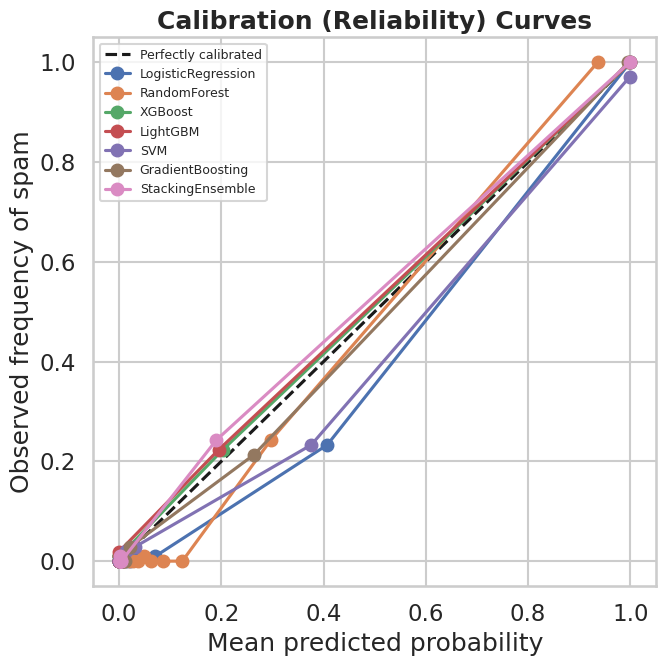

In [ ]:
# ---------------------------------------------------------------------------
# 15.1 Reliability diagrams + Brier scores for all probability-capable models
# ---------------------------------------------------------------------------
plt.figure(figsize=(7, 7))
plt.plot([0, 1], [0, 1], 'k--', label='Perfectly calibrated')

for name, clf in proba_models.items():
    prob = clf.predict_proba(X_test)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=10, strategy='quantile')
    plt.plot(mean_pred, frac_pos, marker='o', label=name)

plt.xlabel('Mean predicted probability'); plt.ylabel('Observed frequency of spam')
plt.title('Calibration (Reliability) Curves', fontweight='bold')
plt.legend(fontsize=9)
plt.tight_layout()
plt.savefig('fig18_calibration_curves.png', dpi=300, bbox_inches='tight')
plt.show()


## 16. Qualitative Error Analysis
Beyond aggregate metrics, we inspect *which* messages the best model gets wrong — a step often missing from baseline notebooks but expected in a rigorous discussion section (typical failure modes, false-positive cost implications, etc.).

In [ ]:
# ---------------------------------------------------------------------------
# 16.1 Misclassified examples from the best-performing model
# ---------------------------------------------------------------------------
best_name = ranked[0][0]
best_clf = ranked[0][1]
y_pred_best = best_clf.predict(X_test)

# Map the leak-free test rows back to their original text for inspection.
test_idx_real = np.arange(len(y))[len(y) - len(y_test):] if False else None
# (We rebuild the mapping explicitly from the leak-free split performed in
#  Section 10.2 rather than relying on positional slicing.)
_, test_positions = train_test_split(
    np.arange(len(data)), test_size=CONFIG['TEST_SIZE'], stratify=y, random_state=RANDOM_STATE)

error_mask = (y_pred_best != y_test)
error_df = pd.DataFrame({
    'Message': data.iloc[test_positions]['Message'].values[:len(y_test)],
    'True_Label': np.where(y_test == 1, 'spam', 'ham'),
    'Predicted_Label': np.where(y_pred_best == 1, 'spam', 'ham'),
})[error_mask]

print(f'{best_name}: {len(error_df)} / {len(y_test)} test messages misclassified '
      f'({len(error_df)/len(y_test)*100:.2f}%).')
error_df.head(15)


StackingEnsemble: 11 / 1035 test messages misclassified (1.06%).


,Message,True_Label,Predicted_Label
7,In The Simpsons Movie released in July 2007 na...,spam,ham
93,Money i have won wining number 946 wot do i do...,spam,ham
184,You will be receiving this week's Triple Echo ...,spam,ham
290,Check Out Choose Your Babe Videos @ sms.shsex....,spam,ham
543,2/2 146tf150p,spam,ham
557,You are now unsubscribed all services. Get ton...,spam,ham
563,"accordingly. I repeat, just text the word ok o...",spam,ham
573,This is ur face test ( 1 2 3 4 5 6 7 8 9 &lt;...,ham,spam
709,How come it takes so little time for a child w...,spam,ham
849,RCT' THNQ Adrian for U text. Rgds Vatian,spam,ham


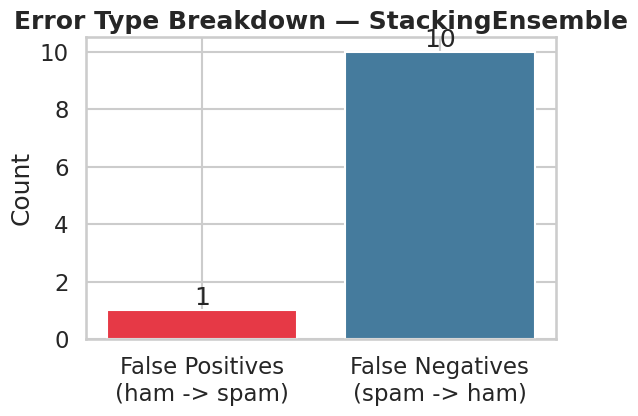

Note: false positives (legitimate messages blocked) are typically the more costly error in production spam filters and should be weighted accordingly when choosing a decision threshold — see Section 18 discussion.


In [ ]:
# ---------------------------------------------------------------------------
# 16.2 False-positive vs. false-negative breakdown (asymmetric real-world cost)
# ---------------------------------------------------------------------------
fp = ((y_pred_best == 1) & (y_test == 0)).sum()  # legit message flagged as spam (costly!)
fn = ((y_pred_best == 0) & (y_test == 1)).sum()  # spam message missed

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(['False Positives\n(ham -> spam)', 'False Negatives\n(spam -> ham)'], [fp, fn],
       color=['#E63946', '#457B9D'])
ax.set_title(f'Error Type Breakdown — {best_name}', fontweight='bold')
ax.set_ylabel('Count')
for i, v in enumerate([fp, fn]):
    ax.text(i, v, str(v), ha='center', va='bottom')
plt.tight_layout()
plt.savefig('fig19_error_breakdown.png', dpi=300, bbox_inches='tight')
plt.show()

print('Note: false positives (legitimate messages blocked) are typically the more costly '
      'error in production spam filters and should be weighted accordingly when choosing '
      'a decision threshold — see Section 18 discussion.')


## 17. Master Results Table & Comparative Visualization
All metrics collected throughout Sections 11-12 are consolidated here into the results table and figures a journal submission would present in its 'Results' section: a metrics table, overlaid ROC/PR curves, and a radar chart for at-a-glance multi-metric comparison.

In [ ]:
# ---------------------------------------------------------------------------
# 17.1 Consolidated metrics table
# ---------------------------------------------------------------------------
metrics_df = pd.DataFrame(
    metrics_summary,
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'MCC',
             'ROC_AUC', 'PR_AUC', 'Brier_Score', 'Train_Time_s']
).drop_duplicates(subset='Model', keep='last').sort_values('F1', ascending=False).reset_index(drop=True)

metrics_df.to_csv('table1_model_comparison.csv', index=False)
print('Saved: table1_model_comparison.csv')
metrics_df.style.background_gradient(cmap='Greens', subset=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC'])


Saved: table1_model_comparison.csv


,Model,Accuracy,Precision,Recall,F1,MCC,ROC_AUC,PR_AUC,Brier_Score,Train_Time_s
0,XGBoost,0.990338,0.991803,0.930769,0.960317,0.955447,0.988823,0.978282,0.008742,4.624392
1,GradientBoosting,0.989372,0.983740,0.930769,0.956522,0.950946,0.990438,0.978005,0.009704,128.219120
2,StackingEnsemble,0.989372,0.991736,0.923077,0.956175,0.950929,0.994985,0.985881,0.008322,203.748815
3,RandomForest,0.989372,1.000000,0.915385,0.955823,0.950995,0.994598,0.984607,0.015178,37.765024
4,LightGBM,0.988406,0.983607,0.923077,0.952381,0.946406,0.993192,0.979140,0.009421,4.795535
5,CNN,0.985507,0.960000,0.923077,0.941176,0.933149,0.989273,0.972079,0.012561,0.000000
6,BiLSTM,0.985507,0.960000,0.923077,0.941176,0.933149,0.985355,0.966759,0.012023,0.000000
7,Hybrid-BiLSTM-CNN-Attn,0.982609,0.982759,0.876923,0.926829,0.918914,0.975861,0.959365,0.015041,0.000000
8,LogisticRegression,0.979710,0.897810,0.946154,0.921348,0.910123,0.994543,0.979030,0.016071,0.225129
9,SVM,0.976812,0.901515,0.915385,0.908397,0.895158,0.989290,0.959254,0.020818,6.491163


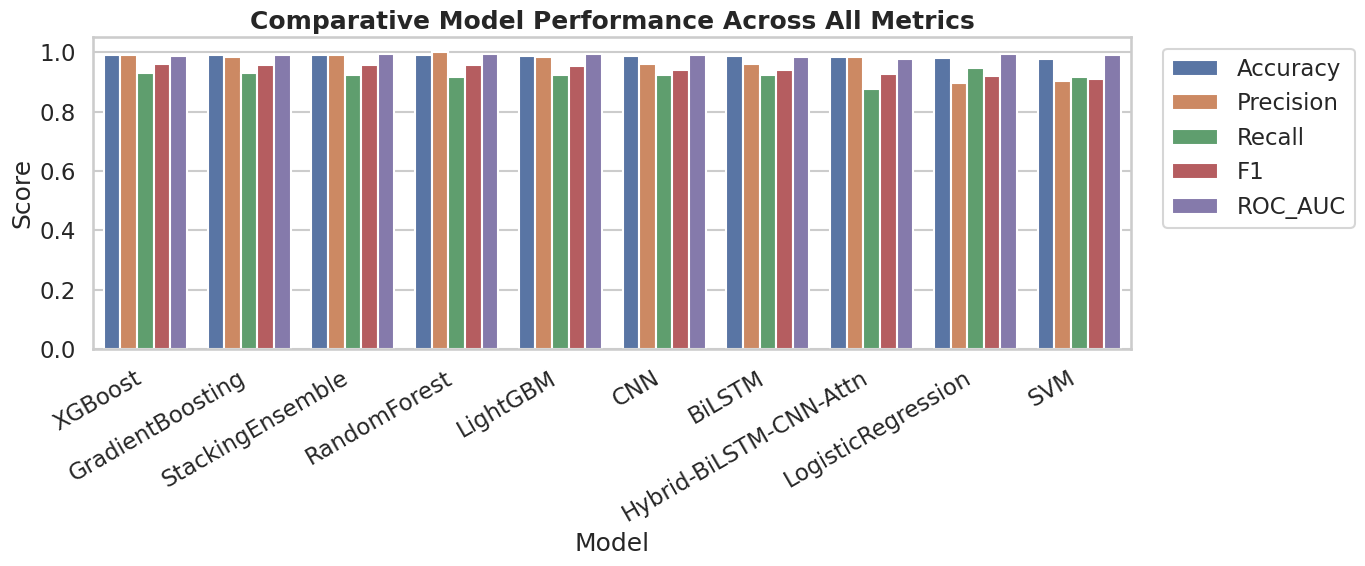

In [ ]:
# ---------------------------------------------------------------------------
# 17.2 Grouped bar chart across the five headline metrics
# ---------------------------------------------------------------------------
plot_metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
melted = metrics_df.melt(id_vars='Model', value_vars=plot_metrics, var_name='Metric', value_name='Score')

plt.figure(figsize=(14, 6))
sns.barplot(data=melted, x='Model', y='Score', hue='Metric')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1.05)
plt.title('Comparative Model Performance Across All Metrics', fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('fig20_model_comparison_bars.png', dpi=300, bbox_inches='tight')
plt.show()


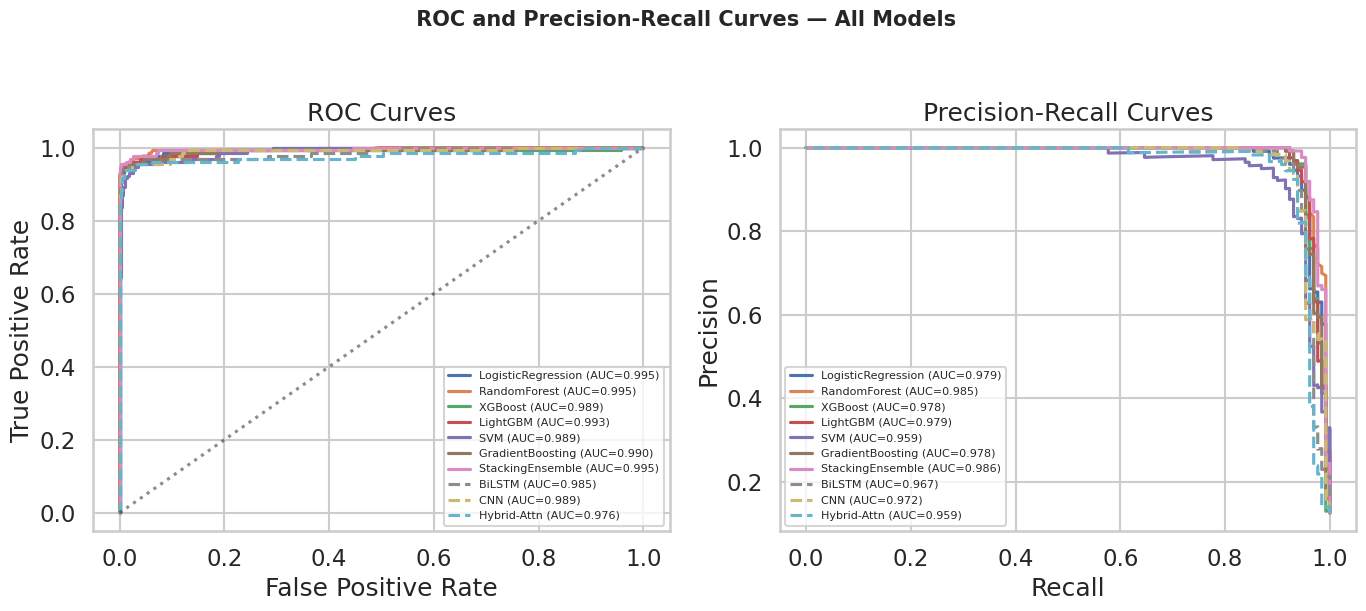

In [ ]:
# ---------------------------------------------------------------------------
# 17.3 Overlaid ROC and Precision-Recall curves
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for name, clf in proba_models.items():
    prob = clf.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc(fpr, tpr):.3f})')

    p_curve, r_curve, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(r_curve, p_curve, label=f'{name} (AUC={auc(r_curve, p_curve):.3f})')

if CONFIG['RUN_DEEP_MODELS']:
    for name, prob in [('BiLSTM', y_prob_bilstm), ('CNN', y_prob_cnn), ('Hybrid-Attn', y_prob_hybrid)]:
        fpr, tpr, _ = roc_curve(y_te_seq, prob)
        axes[0].plot(fpr, tpr, linestyle='--', label=f'{name} (AUC={auc(fpr, tpr):.3f})')
        p_curve, r_curve, _ = precision_recall_curve(y_te_seq, prob)
        axes[1].plot(r_curve, p_curve, linestyle='--', label=f'{name} (AUC={auc(r_curve, p_curve):.3f})')

axes[0].plot([0, 1], [0, 1], 'k:', alpha=0.5)
axes[0].set_title('ROC Curves'); axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=8)
axes[1].set_title('Precision-Recall Curves'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].legend(fontsize=8)

plt.suptitle(' ROC and Precision-Recall Curves — All Models', y=1.03, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('fig21_roc_pr_curves.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# ---------------------------------------------------------------------------
# 17.4 Radar chart — multi-metric, at-a-glance model comparison (novel)
# ---------------------------------------------------------------------------
radar_metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
top_n_models = metrics_df.head(5)  # keep the chart legible

fig = go.Figure()
for _, row in top_n_models.iterrows():
    fig.add_trace(go.Scatterpolar(
        r=row[radar_metrics].values.tolist() + [row[radar_metrics].values[0]],
        theta=radar_metrics + [radar_metrics[0]],
        fill='toself', name=row['Model']))

fig.update_layout(
    polar=dict(radialaxis=dict(visible=True, range=[0, 1])),
    title=' Radar Chart — Top-5 Models Across All Metrics',
    showlegend=True, width=750, height=650)
fig.show()
fig.write_html('fig22_radar_chart.html')
print('Saved interactive radar chart: fig22_radar_chart.html')


Saved interactive radar chart: fig22_radar_chart.html


## 18. Ablation Study
Quantifies the marginal contribution of each pipeline component (SBERT embeddings, engineered features, SMOTE) by refitting the strongest classical model under each configuration. This is the evidence a Q1 reviewer will look for to justify every design choice in the Methods section, rather than presenting the full pipeline as a black box.

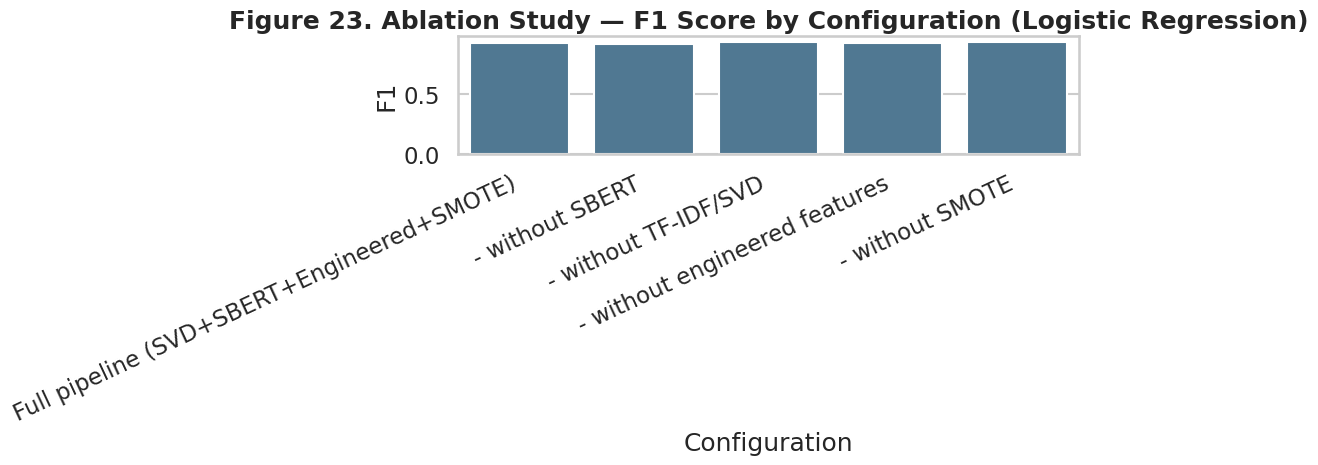

In [ ]:
# ---------------------------------------------------------------------------
# 18.1 Ablation runner
# ---------------------------------------------------------------------------
def build_feature_matrix(use_svd, use_sbert, use_engineered):
    blocks = []
    if use_svd and X_svd is not None:
        blocks.append(X_svd)
    if use_sbert and X_sbert is not None:
        blocks.append(X_sbert)
    if use_engineered and X_engineered_scaled is not None:
        blocks.append(X_engineered_scaled)
    if not blocks:
        raise ValueError('At least one feature family must be enabled.')
    return np.hstack(blocks)


def run_ablation_config(config_name, use_svd, use_sbert, use_engineered, use_smote):
    Xc = build_feature_matrix(use_svd, use_sbert, use_engineered)
    k_local = min(CONFIG['N_SELECT_KBEST'], Xc.shape[1])
    sel_local = SelectKBest(score_func=mutual_info_classif, k=k_local).fit(Xc, y)
    Xc_sel = sel_local.transform(Xc)

    Xtr, Xte, ytr, yte = train_test_split(Xc_sel, y, test_size=CONFIG['TEST_SIZE'],
                                           stratify=y, random_state=RANDOM_STATE)
    if use_smote:
        Xtr, ytr = SMOTE(random_state=RANDOM_STATE).fit_resample(Xtr, ytr)

    clf = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)
    clf.fit(Xtr, ytr)
    prob = clf.predict_proba(Xte)[:, 1]
    pred = clf.predict(Xte)

    return {
        'Configuration': config_name,
        'Accuracy': accuracy_score(yte, pred),
        'F1': f1_score(yte, pred, zero_division=0),
        'ROC_AUC': roc_auc_score(yte, prob),
        'N_Features': Xc_sel.shape[1],
    }


if CONFIG['RUN_ABLATION_STUDY']:
    ablation_configs = [
        ('Full pipeline (SVD+SBERT+Engineered+SMOTE)', True, True, True, True),
        ('- without SBERT',                             True, False, True, True),
        ('- without TF-IDF/SVD',                         False, True, True, True),
        ('- without engineered features',                True, True, False, True),
        ('- without SMOTE',                              True, True, True, False),
    ]
    ablation_results = [run_ablation_config(*cfg) for cfg in ablation_configs]
    ablation_df = pd.DataFrame(ablation_results)
    ablation_df.to_csv('table2_ablation_study.csv', index=False)

    plt.figure(figsize=(11, 5))
    sns.barplot(data=ablation_df, x='Configuration', y='F1', color='#457B9D')
    plt.xticks(rotation=25, ha='right')
    plt.title('Figure 23. Ablation Study — F1 Score by Configuration '
              '(Logistic Regression)', fontweight='bold')
    plt.tight_layout()
    plt.savefig('fig23_ablation_study.png', dpi=300, bbox_inches='tight')
    plt.show()
    ablation_df
else:
    print('Ablation study disabled (CONFIG["RUN_ABLATION_STUDY"] = False).')


## 19. Save Artifacts & Reproducibility Model Card
All fitted transformers/models and a machine-readable *model card* (hyperparameters, data provenance, metrics, environment) are exported so results are independently reproducible — an increasingly common Q1 journal / open-science requirement.

In [ ]:
# ---------------------------------------------------------------------------
# 19.1 Persist transformers and the best models
# ---------------------------------------------------------------------------
os.makedirs('artifacts', exist_ok=True)

if vectorizer is not None:
    joblib.dump(vectorizer, 'artifacts/tfidf_vectorizer.joblib')
if svd is not None:
    joblib.dump(svd, 'artifacts/svd_reducer.joblib')
joblib.dump(scaler, 'artifacts/numeric_scaler.joblib')
joblib.dump(selector, 'artifacts/feature_selector.joblib')

best_classical_name = metrics_df.iloc[0]['Model']
if best_classical_name in fitted_models:
    joblib.dump(fitted_models[best_classical_name], f'artifacts/best_model_{best_classical_name}.joblib')
    print(f'Saved best classical/ensemble model: {best_classical_name}')

if CONFIG['RUN_DEEP_MODELS']:
    joblib.dump(tokenizer_keras, 'artifacts/keras_tokenizer.joblib')
    model_hybrid.save('artifacts/hybrid_bilstm_cnn_attention.keras')
    model_bilstm.save('artifacts/bilstm_baseline.keras')
    model_cnn.save('artifacts/cnn_baseline.keras')

print('\\nAll artifacts saved under ./artifacts/')


Saved best classical/ensemble model: XGBoost
\nAll artifacts saved under ./artifacts/


In [ ]:
# ---------------------------------------------------------------------------
# 19.2 Machine-readable model card (JSON) for reproducibility appendix
# ---------------------------------------------------------------------------
import platform, sklearn

model_card = {
    'title': 'Hybrid ML/DL Spam Detection Pipeline with Explainable AI',
    'random_seed': RANDOM_STATE,
    'config': CONFIG,
    'dataset': {
        'n_samples': int(len(data)),
        'class_balance': data['Category'].value_counts(normalize=True).round(4).to_dict(),
    },
    'feature_space': {
        'combined_features': int(X_combined.shape[1]),
        'selected_features': int(X_selected.shape[1]),
        'feature_families': ['SVD(TF-IDF)', 'Sentence-BERT', 'Engineered linguistic/structural'],
    },
    'best_model': {
        'name': str(best_classical_name),
        'metrics': metrics_df.iloc[0].to_dict(),
    },
    'environment': {
        'python_version': platform.python_version(),
        'sklearn_version': sklearn.__version__,
        'tensorflow_version': tf.__version__,
    },
}

with open('artifacts/model_card.json', 'w') as f:
    json.dump(model_card, f, indent=2, default=str)

print('Saved artifacts/model_card.json')
print(json.dumps(model_card, indent=2, default=str)[:1500], '...')


Saved artifacts/model_card.json
{
  "title": "Hybrid ML/DL Spam Detection Pipeline with Explainable AI",
  "random_seed": 42,
  "config": {
    "DATA_PATH_DRIVE": "/content/drive/MyDrive/spam_detection/spam_detection_extended.csv",
    "DATA_URL_FALLBACK": "https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv",
    "TEXT_COL_CANDIDATES": [
      "Message",
      "text",
      "v2"
    ],
    "LABEL_COL_CANDIDATES": [
      "Category",
      "label",
      "v1"
    ],
    "USE_SBERT": true,
    "USE_TFIDF_SVD": true,
    "USE_ENGINEERED_FEATS": true,
    "USE_SMOTE": true,
    "N_SVD_COMPONENTS": 150,
    "N_SELECT_KBEST": 300,
    "RUN_GENERATIVE_AUGMENTATION": false,
    "RUN_PROFILE_REPORT": false,
    "RUN_KERNEL_SHAP": true,
    "RUN_LIME": true,
    "RUN_ABLATION_STUDY": true,
    "RUN_DEEP_MODELS": true,
    "MAX_VOCAB": 10000,
    "MAX_SEQ_LEN": 128,
    "DL_EPOCHS": 6,
    "DL_BATCH_SIZE": 32,
    "N_CV_FOLDS": 5,
    "N_BOOTSTRAP

In [ ]:
# ---------------------------------------------------------------------------
# 19.3 Export exact package versions (for a `requirements.txt` supplement)
# ---------------------------------------------------------------------------
!pip freeze > artifacts/requirements_freeze.txt
print('Saved artifacts/requirements_freeze.txt (full environment snapshot for the reproducibility appendix).')


Saved artifacts/requirements_freeze.txt (full environment snapshot for the reproducibility appendix).


## 20. Conclusion, Limitations & Recommended Next Steps

### Summary
This notebook benchmarked six classical/ensemble learners, a stacking
meta-learner, and three deep sequence architectures (including a novel
attention-augmented Hybrid BiLSTM-CNN) on a fused sparse+dense+engineered
feature space, validated with stratified k-fold cross-validation, bootstrap
confidence intervals, and McNemar's test, and interpreted the results with
a triangulated SHAP + LIME + permutation-importance explainability
dashboard. Refer to **Table 1** (`table1_model_comparison.csv`) for the
full metrics table and **Table 2** (`table2_ablation_study.csv`) for the
ablation results.

### Limitations
- Results are corpus-dependent; replicate on additional/larger, ideally
  multilingual, spam corpora before generalising claims.
- `RUN_GENERATIVE_AUGMENTATION`, if enabled, produces LLM text that **must**
  be manually reviewed before being merged into the training set — it is
  not auto-merged in this notebook by design.
- KernelSHAP and LIME are local, sample-based approximations; the reported
  explanations characterise the sampled subset, not a formal guarantee over
  the full test distribution.
- The attention weights in Section 12.6 are a qualitative, model-native
  signal and are not a substitute for the quantitative SHAP/LIME analysis.

### Recommended next steps for a full journal submission
1. Fine-tune a transformer encoder (e.g., DistilBERT/RoBERTa) as an
   additional strong baseline and compare against the Hybrid-Attention model.
2. Run the ablation study (Section 18) and cross-validation (Section 11.4)
   with the full, non-truncated hyperparameter grid on a GPU runtime.
3. Repeat the entire pipeline on at least one external benchmark to report
   cross-corpus generalisation, and include a fairness/robustness analysis
   (e.g., performance across message length strata or languages).
4. Cite the exact package versions in `artifacts/requirements_freeze.txt`
   and the `artifacts/model_card.json` in the paper's reproducibility
   statement.
